# BFC Competitor Check 2026
## Notebook 04: Exploratory Data Analysis

### Purpose

Explore the prepared evidence against the ten research questions
defined in Notebook 01.

### Study baseline

October 23, 2026.

### Analysis rules

1. Identify the research question for each analysis.
2. Report the observations included and excluded.
3. Preserve collection gaps and evidence qualifications.
4. Keep channels, promotional prices and serving formats separate.
5. Avoid counting repeated captures as independent observations.
6. Treat customer comments as exploratory feedback.
7. Inspect outliers before deciding how to handle them.
8. Use statistical tests only when the data and assumptions support them.

### Initial scope

Describe evidence coverage and missingness before comparing products,
prices, programs, branches or commercial offers.

Missing values do not prove that a brand lacks a product or service.
Prepared data does not mean collection is complete.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (
        project_root
        / "data"
        / "processed"
        / "quality_reports"
        / "field_types.csv"
    ).is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

processed_data_path = project_root / "data" / "processed"
report_path = processed_data_path / "quality_reports"
references_path = project_root / "references"

if not (report_path / "field_types.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project after Notebook 03."
    )

baseline_date = pd.Timestamp("2026-10-23")


# 2. Load field definitions, cleaning decisions and research coverage.

field_types = pd.read_csv(
    report_path / "field_types.csv",
    dtype="string",
)

cleaning_review = pd.read_csv(
    report_path / "cleaning_review.csv",
    dtype="string",
)

coverage_register = pd.read_csv(
    references_path / "collection_coverage_register.csv",
    dtype="string",
)

if field_types.duplicated(["dataset", "field"]).any():
    raise ValueError("Repeated field definitions found.")


# 3. Load prepared datasets and restore saved types.
# CSV files store values, not pandas data types.

datasets = {}

for dataset_name in field_types["dataset"].drop_duplicates():
    file_path = processed_data_path / f"{dataset_name}.csv"
    df = pd.read_csv(file_path, dtype="string")

    definitions = field_types.loc[
        field_types["dataset"].eq(dataset_name)
    ]

    if set(df.columns) != set(definitions["field"]):
        raise ValueError(
            f"Saved columns differ from field definitions: {dataset_name}"
        )

    for row_index, definition in definitions.iterrows():
        field = definition["field"]
        data_type = definition["pandas_dtype"]

        if data_type.startswith("datetime64"):
            df[field] = pd.to_datetime(
                df[field],
                format="%Y-%m-%d",
                errors="raise",
            )
        else:
            df[field] = df[field].astype(data_type)

    datasets[dataset_name] = df


# 4. Describe dataset coverage.
# Brand counts describe collected records, not national coverage.

inventory_rows = []

for dataset_name, df in datasets.items():
    brands_recorded = pd.NA

    if "brand_id" in df.columns:
        brands_recorded = df["brand_id"].nunique()

    inventory_rows.append({
        "dataset": dataset_name,
        "records": len(df),
        "fields": len(df.columns),
        "brands_recorded": brands_recorded,
        "missing_cells": int(df.isna().sum().sum()),
    })

evidence_inventory = pd.DataFrame(inventory_rows)

print("Prepared evidence inventory:")
display(evidence_inventory)


# 5. Bring unresolved decisions into the analysis.

print("\nCleaning decisions and qualifications:")
with pd.option_context("display.max_colwidth", None):
    display(cleaning_review)

print("\nResearch question coverage:")
with pd.option_context("display.max_colwidth", None):
    display(
        coverage_register[
            [
                "research_question_id",
                "research_area",
                "coverage_status",
                "remaining_requirement",
            ]
        ]
    )


# 6. Identify menu observations needing repeat capture review.
# This is a review list, not an automatic exclusion list.

menu_review_ids = cleaning_review.loc[
    cleaning_review["dataset"].eq("menu_pricing"),
    "record_id",
].drop_duplicates()

menu_review_records = datasets["menu_pricing"].loc[
    datasets["menu_pricing"]["observation_id"].isin(menu_review_ids)
]

print("\nMenu observations requiring analysis decisions:")
display(
    menu_review_records[
        [
            "observation_id",
            "brand_id",
            "product_name",
            "source_id",
            "displayed_price_php",
            "promo_price_php",
            "price_basis",
        ]
    ]
)

print("Study baseline:", baseline_date.date())
print("Prepared datasets loaded:", len(datasets))
print("Documented review items:", len(cleaning_review))
print("No records excluded or files changed.")

Prepared evidence inventory:


,dataset,records,fields,brands_recorded,missing_cells
0,competitor_master,23,19,23,107
1,branch_directory,24,15,21,142
2,menu_pricing,246,22,21,1891
3,promotions,3,21,2,20
4,loyalty_programs,4,16,4,11
5,store_assessments,3,21,3,37
6,customer_reviews,36,16,3,180
7,ordering_channels,6,20,4,46
8,franchise_offers,15,27,11,205
9,commercial_developments,7,15,6,17



Cleaning decisions and qualifications:


,dataset,record_id,issue,treatment
0,source_register,SRC0035,Menu request redirected to rewards,Retain audit record. Not accepted as menu or pricing evidence. Missing collection metadata remains unresolved.
1,competitor_master,BFC004,Conflicting founding statements and missing verification date,Retain reported 2022 year and conflicting 2021 statement. Keep verification date missing. First store date unconfirmed.
2,competitor_master,BFC005,Missing verification date,Retain partial verification and existing source qualifications. Do not infer a verification date from source collection dates.
3,competitor_master,BFC012,Missing verification date,Retain partial verification and existing source qualifications. Do not infer a verification date from source collection dates.
4,menu_pricing,MNU0078,Chatime Milk Tea promotional version,Retain alongside MNU0095. Different retrieved price versions. Do not interpret as a dated price change or combine as independent comparable prices.
5,menu_pricing,MNU0095,Chatime Milk Tea recheck version,Retain alongside MNU0078. Effective price and promotion conditions remain unresolved.
6,menu_pricing,MNU0079,Chatime Pearl Milk Tea promotional version,Retain alongside MNU0096. Different retrieved price versions. Do not interpret as a dated price change or combine as independent comparable prices.
7,menu_pricing,MNU0096,Chatime Pearl Milk Tea recheck version,Retain alongside MNU0079. Effective price and promotion conditions remain unresolved.
8,menu_pricing,MNU0034,Starbucks Latte supported by another capture,Retain alongside MNU0108 for traceability. Do not count both as independent price observations in a single comparison.
9,menu_pricing,MNU0108,Starbucks Latte repeat capture,Retain alongside MNU0034 for traceability. Same displayed price does not resolve serving size.



Research question coverage:


,research_question_id,research_area,coverage_status,remaining_requirement
0,RQ01,Pricing and value,Partial; BFC and CBTL candidate pairs identified,"Confirm price freshness, branch applicability and product equivalence. Resolve sizes and selected variant prices for the other core brands. Keep channels and promotional prices separate. Actual beverage volumes remain unverified."
1,RQ02,Products and food,Partial; selected comparison products collected,Document systematic product and food category coverage for the selected brands. Missing observations do not establish that a product or category is absent.
2,RQ03,Promotions and loyalty,Partial; limited brands and offer mechanics,"Confirm validity, eligibility, qualifying spend, reward values, expiry and exclusions. Separate published program descriptions from verified redemption experience."
3,RQ04,Design and store experience,Partial; published concepts only,"Collect comparable branch observations covering store format, facilities, comfort, service layout and visit conditions. Published concepts are not branch visits."
4,RQ05,Customer feedback,Partial; exploratory platform selected comments,Original newest review samples remain incomplete. Broader coverage and consistent selection are needed. Existing comments lack exact dates and individual ratings and support exploratory qualitative analysis only.
5,RQ06,Ordering and delivery,Partial; published channel descriptions,"Document comparable ordering journeys, customization, payment choices, fees, coverage and waiting times. Published features do not establish checkout availability."
6,RQ07,Branch network,Partial; listed and provisional branches,"Resolve branch identities and aliases, verify geography, formats and operating status, and document the sample. Directory entries do not establish national network size or historical network changes."
7,RQ08,Franchise comparison,Partial; overviews and selected package statements,"Confirm comparable formats, investment definitions, inclusions, exclusions, tax treatment, recurring fees, agreement terms and current Philippine availability. Inquiry pages are not complete package quotations."
8,RQ09,Other commercial offers,Partial; BFC event prices and selected competitor offers,"Collect equivalent competitor package prices, quantities, service scope, inclusions and additional charges. Confirm Philippine applicability and effective dates."
9,RQ10,Historical changes and baseline,Partial; baseline evidence and operating histories,"Original 2024 baseline remains unavailable. Historical change analysis requires independently dated comparable observations. Founding histories do not establish historical price, branch or offer changes. TOMO founding year remains qualified."



Menu observations requiring analysis decisions:


,observation_id,brand_id,product_name,source_id,displayed_price_php,promo_price_php,price_basis
33,MNU0034,BFC022,Caffe Latte,SRC0037,190.0,<NA>,Product card starting price
77,MNU0078,BFC013,Chatime Milk Tea,SRC0048,104.0,104.0,Product card starting price
78,MNU0079,BFC013,Pearl Milk Tea,SRC0048,112.0,112.0,Product card starting price
94,MNU0095,BFC013,Chatime Milk Tea,SRC0056,130.0,<NA>,Product card starting price
95,MNU0096,BFC013,Pearl Milk Tea,SRC0056,140.0,<NA>,Product card starting price
107,MNU0108,BFC022,Caffe Latte,SRC0119,190.0,<NA>,Product card starting price
149,MNU0150,BFC002,ICED AURO CHOCOLATE PISTACHIO LATTE,SRC0125,129.0,<NA>,Product listing price; size not stated
206,MNU0207,BFC001,Americano,SRC0126,110.0,<NA>,Product listing price; size not stated


Study baseline: 2026-10-23
Prepared datasets loaded: 12
Documented review items: 14
No records excluded or files changed.


In [2]:
# Confirm that the complete menu was loaded before filtering.
if len(datasets["menu_pricing"]) != 246:
    raise ValueError(
        "Run the first loading cell again. Expected 246 menu records."
    )

all_datasets = {}

for name, df in datasets.items():
    all_datasets[name] = df.copy()

baseline_date = pd.Timestamp("2026-10-23")

for name, df in all_datasets.items():
    if "observed_date" in df.columns:
        observed_dates = pd.to_datetime(
            df["observed_date"],
            errors="raise"
        )

        datasets[name] = df.loc[
            observed_dates.le(baseline_date)
        ].copy()

print("Complete menu records:", len(all_datasets["menu_pricing"]))
print("Baseline menu records:", len(datasets["menu_pricing"]))

Complete menu records: 246
Baseline menu records: 131


## 1. Evidence Coverage by Brand

### Research question alignment

Supports RQ10 by describing the coverage of the 2026 baseline.
Also identifies evidence limitations affecting RQ01 through RQ09.

### Purpose

Show which brands have collected records in each dataset.

### Interpretation

A positive count means records were collected.
It does not establish complete, comparable or verified coverage.

A zero means no records were collected in that dataset.
It does not establish that the brand lacks the product or service.

The denominator includes all 23 registered brands, including
the reference brand and candidates.

Records collected by brand:


,brand_id,brand_name,inclusion_status,branch_directory,menu_pricing,promotions,loyalty_programs,store_assessments,customer_reviews,ordering_channels,franchise_offers,commercial_developments,event_packages
0,BFC001,"But First, Coffee",Reference,1,31,0,0,1,7,1,1,2,12
1,BFC002,PICKUP COFFEE,Included,1,6,0,1,0,0,2,1,1,0
2,BFC003,Juan Café,Included,1,3,0,0,0,0,0,1,0,0
3,BFC004,TOMO Coffee,Candidate,0,0,0,0,0,0,0,0,0,0
4,BFC005,TOMORO COFFEE,Candidate,1,6,0,0,0,0,1,0,0,0
5,BFC006,Macao Imperial Tea,Included,4,3,0,0,0,0,0,1,0,0
6,BFC007,Black Scoop Cafe,Included,1,3,0,0,0,0,0,0,0,0
7,BFC008,Kurimi Milk Tea Bar,Included,1,2,0,0,1,0,0,0,0,0
8,BFC009,Dunkin',Included,1,6,0,0,0,0,0,0,0,0
9,BFC010,Figaro Coffee,Included,1,4,0,0,0,0,0,0,0,0



Coverage across registered brands:


,dataset,records,brands_with_records,registered_brands,coverage_percent
0,branch_directory,24,21,23,91.3
1,menu_pricing,131,21,23,91.3
2,promotions,1,1,23,4.3
3,loyalty_programs,3,3,23,13.0
4,store_assessments,3,3,23,13.0
5,customer_reviews,36,3,23,13.0
6,ordering_channels,5,4,23,17.4
7,franchise_offers,15,11,23,47.8
8,commercial_developments,7,6,23,26.1
9,event_packages,12,1,23,4.3


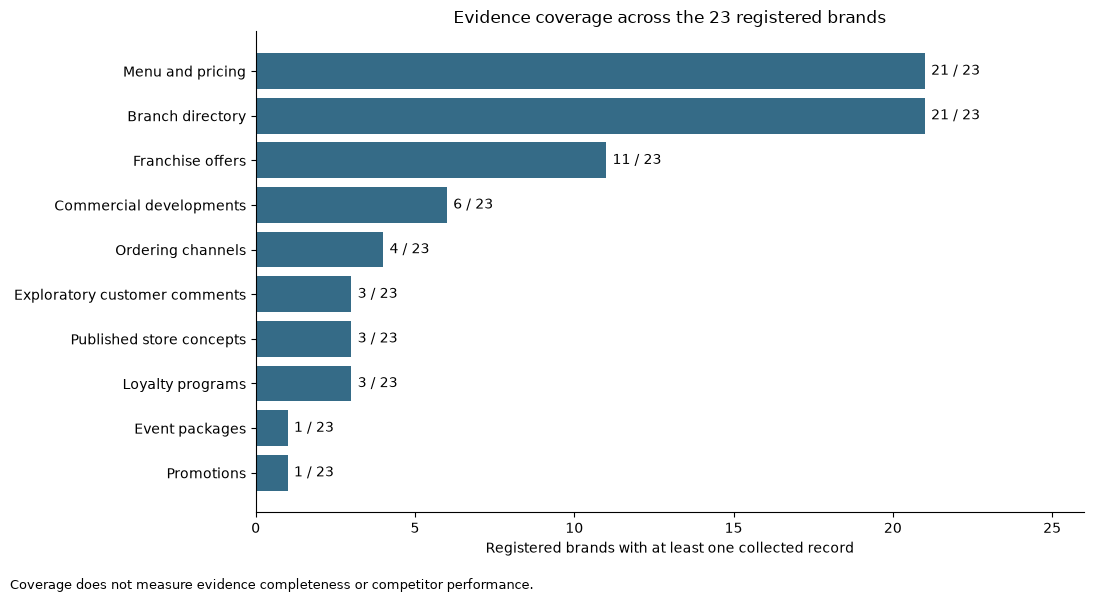

Counts include retained rechecks and qualified evidence.
Published store concepts are not branch visit assessments.
No records excluded or files changed.


In [3]:

import matplotlib.pyplot as plt


# 1. Build a coverage table using all registered brands.

brands = datasets["competitor_master"][
    ["brand_id", "brand_name", "inclusion_status"]
].copy()

coverage_datasets = [
    "branch_directory",
    "menu_pricing",
    "promotions",
    "loyalty_programs",
    "store_assessments",
    "customer_reviews",
    "ordering_channels",
    "franchise_offers",
    "commercial_developments",
    "event_packages",
]

brand_coverage = brands.copy()
coverage_rows = []

for dataset_name in coverage_datasets:
    df = datasets[dataset_name]

    counts = df.groupby("brand_id").size()

    brand_coverage[dataset_name] = (
        brand_coverage["brand_id"]
        .map(counts)
        .fillna(0)
        .astype("Int64")
    )

    brands_with_records = int(
        brand_coverage[dataset_name].gt(0).sum()
    )

    coverage_rows.append({
        "dataset": dataset_name,
        "records": len(df),
        "brands_with_records": brands_with_records,
        "registered_brands": len(brands),
        "coverage_percent": round(
            brands_with_records / len(brands) * 100,
            1,
        ),
    })

coverage_summary = pd.DataFrame(coverage_rows)

print("Records collected by brand:")
with pd.option_context("display.max_columns", None):
    display(brand_coverage)

print("\nCoverage across registered brands:")
display(coverage_summary)


# 2. Visualise the number of brands with any collected records.

chart_data = coverage_summary.sort_values(
    "brands_with_records"
)

chart_labels = {
    "branch_directory": "Branch directory",
    "menu_pricing": "Menu and pricing",
    "promotions": "Promotions",
    "loyalty_programs": "Loyalty programs",
    "store_assessments": "Published store concepts",
    "customer_reviews": "Exploratory customer comments",
    "ordering_channels": "Ordering channels",
    "franchise_offers": "Franchise offers",
    "commercial_developments": "Commercial developments",
    "event_packages": "Event packages",
}

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    chart_data["dataset"].map(chart_labels),
    chart_data["brands_with_records"],
    color="#356B87",
)

for position, count in enumerate(chart_data["brands_with_records"]):
    ax.text(
        count + 0.2,
        position,
        f"{count} / {len(brands)}",
        va="center",
    )

ax.set_xlim(0, len(brands) + 3)
ax.set_xlabel("Registered brands with at least one collected record")
ax.set_title("Evidence coverage across the 23 registered brands")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.01,
    0.01,
    "Coverage does not measure evidence completeness or competitor performance.",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

print("Counts include retained rechecks and qualified evidence.")
print("Published store concepts are not branch visit assessments.")
print("No records excluded or files changed.")

### Coverage findings

Menu and branch records cover 21 of the 23 registered brands.
This measures collected evidence, not complete market coverage.

Reviews cover three brands and consist of exploratory comments.
Store assessments contain published concepts rather than branch visits.

Event package prices cover BFC only. Franchise records include
different formats and evidence depths.

The analysis will therefore use defined subsets for each research
question rather than combine all records into a single ranking.

RQ01: Candidate published menu price comparison


,comparison_group,temperature,size_label_standardised,displayed_price_php_bfc,displayed_price_php_cbtl,cbtl_minus_bfc_php,source_id_bfc,source_id_cbtl
0,Americano,Hot,12oz,110.0,140.0,30.0,SRC0030,SRC0121
1,Americano,Hot,16oz,120.0,155.0,35.0,SRC0030,SRC0121
6,Cafe latte,Hot,12oz,130.0,135.0,5.0,SRC0031,SRC0121
7,Cafe latte,Hot,16oz,140.0,150.0,10.0,SRC0031,SRC0121
10,Spanish latte,Hot,12oz,130.0,175.0,45.0,SRC0032,SRC0121
11,Spanish latte,Hot,16oz,140.0,185.0,45.0,SRC0032,SRC0121
2,Americano,Iced,12oz,110.0,140.0,30.0,SRC0030,SRC0121
3,Americano,Iced,16oz,120.0,155.0,35.0,SRC0030,SRC0121
4,Cafe latte,Iced,12oz,130.0,135.0,5.0,SRC0031,SRC0121
5,Cafe latte,Iced,16oz,140.0,150.0,10.0,SRC0031,SRC0121


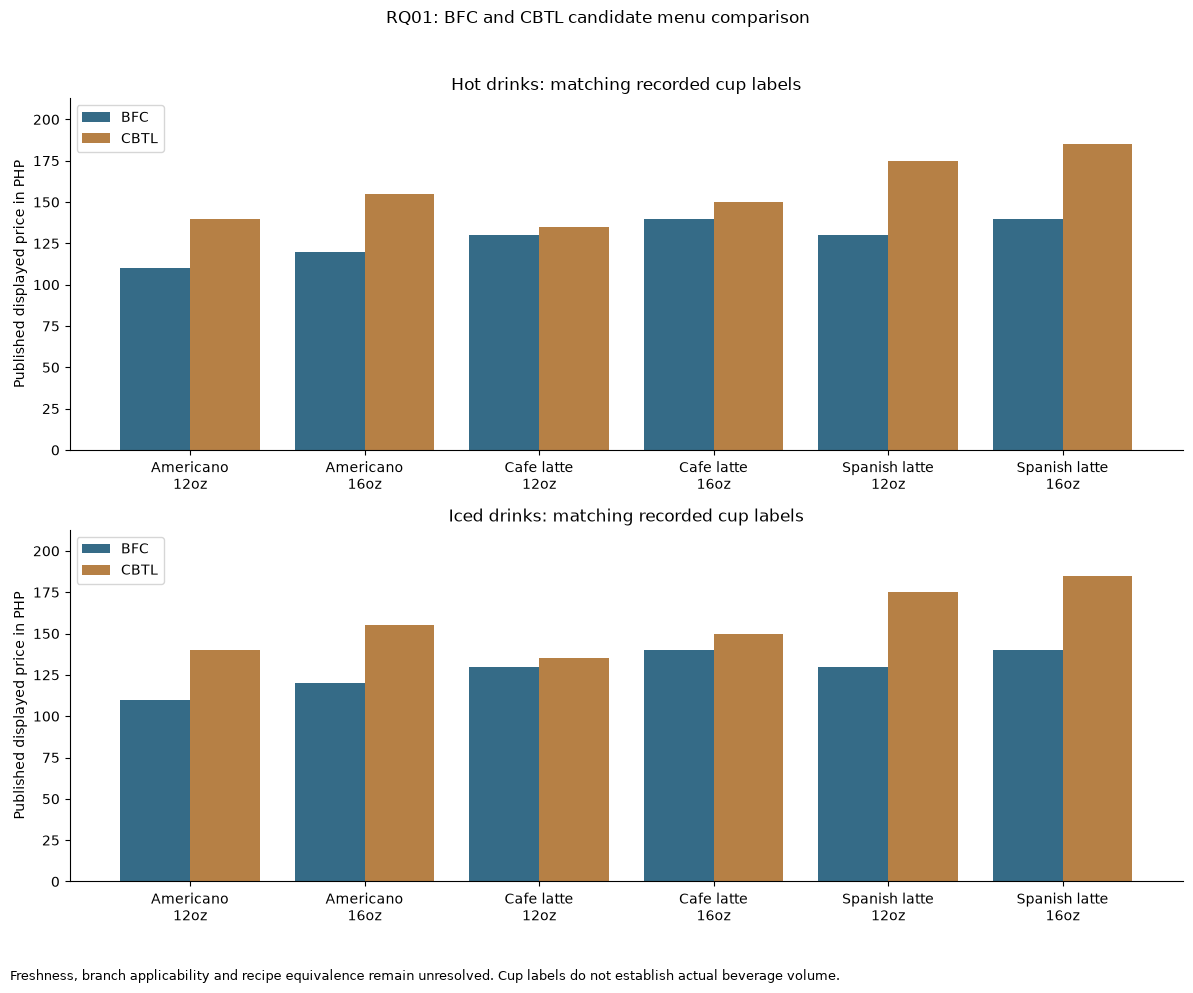

Candidate pairs: 12
Differences describe the recorded menus, not confirmed savings.
No records excluded from the saved datasets. No files changed.


In [4]:
# 1. Select the documented official menu variants.

menu = datasets["menu_pricing"]

pricing_subset = menu.loc[
    menu["source_id"].isin([
        "SRC0030", "SRC0031", "SRC0032", "SRC0121"
    ])
    & menu["brand_id"].isin(["BFC001", "BFC023"])
    & menu["channel"].eq("Official website")
    & menu["temperature"].isin(["Hot", "Iced"])
    & menu["size_label_standardised"].isin(["12oz", "16oz"])
    & menu["price_basis"].eq("Explicit variant")
    & menu["displayed_price_php"].notna()
].copy()

match_fields = [
    "comparison_group",
    "temperature",
    "size_label_standardised",
    "channel",
]

if pricing_subset.duplicated(
    ["brand_id"] + match_fields
).any():
    raise ValueError("Multiple records found for a selected variant.")

selected_fields = match_fields + [
    "observation_id",
    "source_id",
    "displayed_price_php",
]

bfc_prices = pricing_subset.loc[
    pricing_subset["brand_id"].eq("BFC001"),
    selected_fields,
]

cbtl_prices = pricing_subset.loc[
    pricing_subset["brand_id"].eq("BFC023"),
    selected_fields,
]


# 2. Match the recorded definitions and calculate displayed differences.

price_pairs = bfc_prices.merge(
    cbtl_prices,
    on=match_fields,
    how="inner",
    suffixes=("_bfc", "_cbtl"),
    validate="one_to_one",
)

price_pairs["cbtl_minus_bfc_php"] = (
    price_pairs["displayed_price_php_cbtl"]
    - price_pairs["displayed_price_php_bfc"]
)

price_pairs = price_pairs.sort_values(
    ["temperature", "comparison_group", "size_label_standardised"]
)

print("RQ01: Candidate published menu price comparison")
display(
    price_pairs[
        [
            "comparison_group",
            "temperature",
            "size_label_standardised",
            "displayed_price_php_bfc",
            "displayed_price_php_cbtl",
            "cbtl_minus_bfc_php",
            "source_id_bfc",
            "source_id_cbtl",
        ]
    ]
)


# 3. Plot each variant without pooling products or temperatures.

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for ax, temperature in zip(axes, ["Hot", "Iced"]):
    chart_data = price_pairs.loc[
        price_pairs["temperature"].eq(temperature)
    ].copy()

    chart_data["variant"] = (
        chart_data["comparison_group"]
        + "\n"
        + chart_data["size_label_standardised"]
    )

    positions = list(range(len(chart_data)))

    ax.bar(
        [position - 0.2 for position in positions],
        chart_data["displayed_price_php_bfc"].astype(float),
        width=0.4,
        label="BFC",
        color="#356B87",
    )

    ax.bar(
        [position + 0.2 for position in positions],
        chart_data["displayed_price_php_cbtl"].astype(float),
        width=0.4,
        label="CBTL",
        color="#B68045",
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(chart_data["variant"])
    ax.set_ylabel("Published displayed price in PHP")
    ax.set_title(f"{temperature} drinks: matching recorded cup labels")
    ax.set_ylim(
        0,
        float(
            price_pairs[
                ["displayed_price_php_bfc", "displayed_price_php_cbtl"]
            ].max().max()
        ) * 1.15,
    )
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("RQ01: BFC and CBTL candidate menu comparison")

fig.text(
    0.01,
    0.01,
    "Freshness, branch applicability and recipe equivalence remain unresolved. "
    "Cup labels do not establish actual beverage volume.",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

print("Candidate pairs:", len(price_pairs))
print("Differences describe the recorded menus, not confirmed savings.")
print("No records excluded from the saved datasets. No files changed.")

### RQ01 Findings

Within the selected official menu records, BFC has lower displayed
prices than CBTL for all 12 candidate variants.

The smallest differences are for Cafe Latte, ranging from PHP 5
to PHP 10. Spanish Latte has the largest difference at PHP 45.

### Business implication

These records suggest a potential price positioning distinction,
particularly for Spanish Latte. Confirm current branch prices and
product equivalence before using the differences in sales materials.

### Limitations

Matching drink names and cup labels does not establish equivalent
recipes, actual beverage volume, quality or customer value.

Price freshness and branch applicability remain unresolved.
The findings describe selected published menus and cannot establish
a market wide pricing advantage.

## 2. Observed Product Categories

### Research question

RQ02: Which products and food categories are offered, and where
are the gaps?

### Purpose

Describe product categories represented in the collected evidence.

### Method

Count records, brands and sources by recorded product category.
Display category coverage across all registered brands.

### Limitations

Collection focused on selected comparison products.
Counts do not represent complete menus, sales or popularity.

Zero records mean no category evidence was entered.
They do not establish that a brand lacks that category.

Product names may include size and temperature variants.
Distinct recorded names are not necessarily distinct products.

Menu records: 131
Explicitly unavailable options set aside: 3
Remaining listing records: 128

Observed product category profile:


,product_category,listing_records,brands_recorded,sources_recorded,distinct_recorded_names
0,Coffee,103,13,22,36
3,Milk tea,13,5,7,10
1,Fries,4,1,1,4
2,Fruit shakes,3,1,1,3
4,Pastries,2,1,1,2
5,Waffles,3,1,1,3



Listing records by brand and recorded category:


,brand_id,brand_name,inclusion_status,Coffee,Fries,Fruit shakes,Milk tea,Pastries,Waffles
0,BFC001,"But First, Coffee",Reference,26,0,0,0,2,0
1,BFC002,PICKUP COFFEE,Included,6,0,0,0,0,0
2,BFC003,Juan Café,Included,3,0,0,0,0,0
3,BFC004,TOMO Coffee,Candidate,0,0,0,0,0,0
4,BFC005,TOMORO COFFEE,Candidate,6,0,0,0,0,0
5,BFC006,Macao Imperial Tea,Included,0,0,0,3,0,0
6,BFC007,Black Scoop Cafe,Included,3,0,0,0,0,0
7,BFC008,Kurimi Milk Tea Bar,Included,0,0,0,2,0,0
8,BFC009,Dunkin',Included,6,0,0,0,0,0
9,BFC010,Figaro Coffee,Included,4,0,0,0,0,0


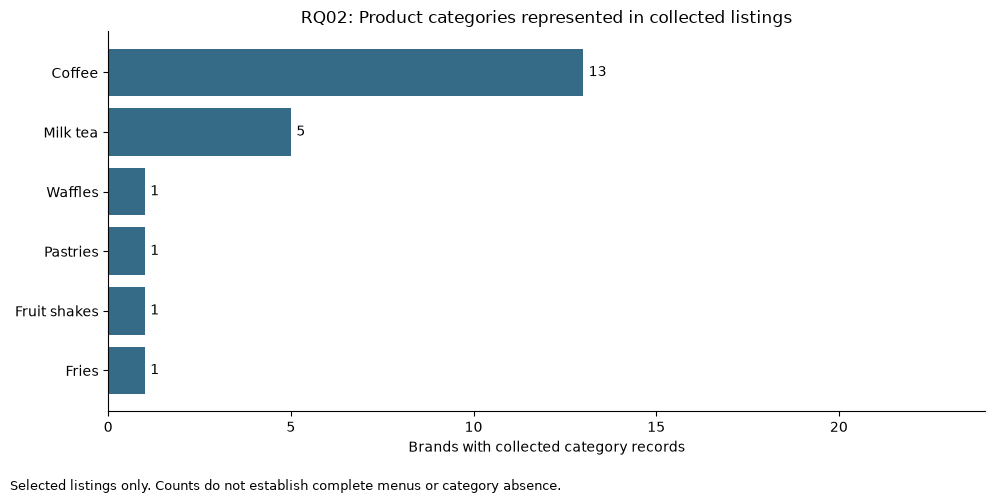

Retained listing records may include rechecks and unconfirmed availability.
No saved records removed or files changed.


In [5]:
# 1. Separate explicitly unavailable options for this description.
# Other listing qualifications remain visible in the underlying records.

menu = datasets["menu_pricing"]

unavailable_mask = (
    menu["availability_status"]
    .str.casefold()
    .eq("unavailable")
    .fillna(False)
)

observed_products = menu.loc[~unavailable_mask].copy()

print("Menu records:", len(menu))
print("Explicitly unavailable options set aside:", int(unavailable_mask.sum()))
print("Remaining listing records:", len(observed_products))


# 2. Summarise the recorded categories.

category_profile = (
    observed_products.groupby(
        "product_category",
        dropna=False,
    )
    .agg(
        listing_records=("observation_id", "size"),
        brands_recorded=("brand_id", "nunique"),
        sources_recorded=("source_id", "nunique"),
        distinct_recorded_names=("product_name", "nunique"),
    )
    .reset_index()
    .sort_values("brands_recorded", ascending=False)
)

print("\nObserved product category profile:")
display(category_profile)


# 3. Show category evidence across all registered brands.

category_counts = pd.crosstab(
    observed_products["brand_id"],
    observed_products["product_category"],
)

registered_brands = datasets["competitor_master"][
    ["brand_id", "brand_name", "inclusion_status"]
].copy()

brand_category_coverage = registered_brands.merge(
    category_counts,
    left_on="brand_id",
    right_index=True,
    how="left",
    validate="one_to_one",
)

category_columns = category_counts.columns.tolist()

for column in category_columns:
    brand_category_coverage[column] = (
        brand_category_coverage[column]
        .fillna(0)
        .astype("Int64")
    )

print("\nListing records by brand and recorded category:")
with pd.option_context("display.max_columns", None):
    display(brand_category_coverage)


# 4. Visualise brand coverage, not menu size.

chart_data = category_profile.loc[
    category_profile["product_category"].notna()
].sort_values("brands_recorded")

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    chart_data["product_category"],
    chart_data["brands_recorded"],
    color="#356B87",
)

for position, count in enumerate(chart_data["brands_recorded"]):
    ax.text(
        count + 0.15,
        position,
        str(count),
        va="center",
    )

ax.set_xlim(0, len(registered_brands) + 1)
ax.set_xlabel("Brands with collected category records")
ax.set_title("RQ02: Product categories represented in collected listings")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.01,
    0.01,
    "Selected listings only. Counts do not establish complete menus or category absence.",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

print("Retained listing records may include rechecks and unconfirmed availability.")
print("No saved records removed or files changed.")

### RQ02 Findings

The collected listings cover five categories: coffee, milk tea,
fries, fruit shakes and waffles.

Coffee accounts for 103 of 126 retained listing records and covers
13 brands. Milk tea covers five brands. Each remaining category
has records from one brand.

### Business implication

The current evidence supports selected product comparisons.
It cannot establish complete menu breadth or recommend new
categories based on apparent gaps.

### Collection limitation

BFC has only coffee records in this dataset, although previously
captured menu text also mentioned matcha and other beverages.
Those categories have not been systematically entered.

The same limitation applies to competitors. Zero records must
not be interpreted as a missing product offering.

RQ02 remains partially answered.

### RQ02 Findings

The collected listings cover five categories: coffee, milk tea,
fries, fruit shakes and waffles.

Coffee accounts for 103 of 126 retained listing records and covers
13 brands. Milk tea covers five brands. Each remaining category
has records from one brand.

### Business implication

The current evidence supports selected product comparisons.
It cannot establish complete menu breadth or recommend new
categories based on apparent gaps.

### Collection limitation

BFC has only coffee records in this dataset, although previously
captured menu text also mentioned matcha and other beverages.
Those categories have not been systematically entered.

The same limitation applies to competitors. Zero records must
not be interpreted as a missing product offering.

RQ02 remains partially answered.

## 3. Promotions and Loyalty

### Research question

RQ03: How do promotions and loyalty benefits compare?

### Purpose

Identify which offer conditions and program rules are documented.

### Comparison rules

Compare benefits only when qualifying spend, reward value,
eligibility and restrictions are sufficiently established.

Keep introductory offers separate from ongoing loyalty benefits.
Keep reward redemption levels separate from membership tiers.

Missing records do not establish that a brand has no program.
Published benefits do not confirm successful redemption.

In [6]:
# 1. Add brand names to temporary analysis tables.

brand_names = datasets["competitor_master"][
    ["brand_id", "brand_name"]
]

promotion_analysis = datasets["promotions"].merge(
    brand_names,
    on="brand_id",
    how="left",
    validate="many_to_one",
)

loyalty_analysis = datasets["loyalty_programs"].merge(
    brand_names,
    on="brand_id",
    how="left",
    validate="many_to_one",
)


# 2. Inspect promotion mechanics and numerical inputs.

print("RQ03: Recorded promotion terms")

with pd.option_context("display.max_colwidth", None):
    display(
        promotion_analysis[
            [
                "promotion_id",
                "brand_name",
                "offer_name",
                "offer_type",
                "mechanics",
                "eligibility",
                "start_date",
                "end_date",
                "channel",
                "location_scope",
                "minimum_spend_php",
                "discount_value",
                "discount_unit",
                "maximum_discount_php",
                "redemption_limit",
                "exclusions",
                "availability_status",
                "source_id",
                "notes",
            ]
        ].T
    )


# 3. Inspect loyalty earning, redemption and restrictions.

print("\nRQ03: Recorded loyalty rules")

with pd.option_context("display.max_colwidth", None):
    display(
        loyalty_analysis[
            [
                "program_version_id",
                "brand_name",
                "program_name",
                "observed_date",
                "effective_date",
                "enrollment_rules",
                "earning_rules",
                "redemption_rules",
                "expiry_rules",
                "tier_rules",
                "benefits",
                "channel",
                "location_scope",
                "exclusions",
                "source_id",
                "notes",
            ]
        ].T
    )


# 4. Display the primary sources used by these records.
# Additional supporting references may also be recorded in notes.

rq03_source_ids = pd.concat(
    [
        promotion_analysis["source_id"],
        loyalty_analysis["source_id"],
    ],
    ignore_index=True,
).dropna().drop_duplicates()

print("\nPrimary source qualifications:")

with pd.option_context("display.max_colwidth", None):
    display(
        datasets["source_register"].loc[
            datasets["source_register"]["source_id"].isin(
                rq03_source_ids
            ),
            [
                "source_id",
                "source_title",
                "source_url",
                "published_date",
                "effective_date",
                "collected_date",
                "verification_status",
                "notes",
            ],
        ]
    )

print("\nPromotion records:", len(promotion_analysis))
print("Loyalty program records:", len(loyalty_analysis))
print("No savings or reward values calculated.")
print("No files changed.")

RQ03: Recorded promotion terms


,0
promotion_id,PRM0001
brand_name,ZUS Coffee
offer_name,Introductory Buy 1 Free 1
offer_type,Additional product offer
mechanics,Download app; advertised Buy 1 Free 1. Full qualifying purchase mechanics unresolved.
eligibility,First time app users; terms apply
start_date,NaT
end_date,NaT
channel,ZUS App
location_scope,Philippine website; participating branches unresolved



RQ03: Recorded loyalty rules


,0,1,2
program_version_id,LOY0001,LOY0002,LOY0003
brand_name,ZUS Coffee,PICKUP COFFEE,Starbucks
program_name,ZUS Coffee Club,PICKUP Club,Starbucks Rewards multitier
observed_date,2026-10-23 00:00:00,2026-10-23 00:00:00,2026-10-23 00:00:00
effective_date,NaT,NaT,NaT
enrollment_rules,Account registration automatically joins membership,Free membership through app registration,Registered account and card
earning_rules,App purchases earn points; earning rate unresolved,Purchase points; earning rate unresolved,One Star per PHP 25 qualifying card spend in store; one per PHP 40 linked Grab or Lazada spend.
redemption_rules,Points redeemable for rewards including free drinks and vouchers; thresholds unresolved,"Vouchers, cashback, merchandise. Advertised up to PHP 500 off for 10000 points; conditions unresolved.","50 Stars: customization or selected bakery products; 100 Stars: handcrafted drink or bakery product; 150 Stars: pasta, sandwich, or cake slice. App reward selection before ordering in store. Reward applies to the highest priced eligible item."
expiry_rules,<NA>,<NA>,"Stars one year, anniversary expiry; vouchers 90 days"
tier_rules,Elite described; qualification thresholds unresolved,"Bronze to Silver 1500 points; Gold 6000; Emerald 12000 over 90 days. Maintenance thresholds 1500, 6000, 12000 respectively over 90 days.",<NA>



Primary source qualifications:


,source_id,source_title,source_url,published_date,effective_date,collected_date,verification_status,notes
58,SRC0059,ZUS Philippine rewards and app page,https://zuscoffee.ph/rewards/,NaT,NaT,2026-10-23,Verified,"Selected inspected statements, not a full page capture. Verification concerns transcription accuracy. Publication and effective dates unresolved. No independent performance or checkout verification."
63,SRC0064,PICKUP Club working official page,https://pickup-coffee.com/pickup-club,NaT,NaT,2026-10-23,Verified,"Selected inspected statements, not full page capture. Retrieved 2026-10-23. Effective dates unresolved unless specified. Verification concerns transcription accuracy, not performance."
65,SRC0066,Starbucks Philippine multitier rewards,https://starbuckscard.ph/sbcard/multitier,NaT,NaT,2026-10-23,Verified,"Selected inspected statements, not full page capture. Retrieved 2026-10-23. Effective dates unresolved unless specified. Verification concerns transcription accuracy, not performance."



Promotion records: 1
Loyalty program records: 3
No savings or reward values calculated.
No files changed.


### RQ03 Findings

The October 23 baseline contains one promotion record and three loyalty
programme records. The complete prepared data contains three promotions
and four loyalty records. The additional observations belong to the
October 25 supplementary review and are assessed separately.

ZUS publishes a Buy 1 Free 1 introductory offer, but its complete
qualifying conditions are unresolved. A universal 50 percent saving
cannot be calculated.

PICKUP publishes membership tiers and selected benefits. Tier point
thresholds do not establish the required customer spending because
the points earning rate remains unresolved.

Starbucks has the most detailed recorded earning and redemption
rules. Earning rates differ by channel. Its redemption levels are
reward choices rather than membership status tiers.

### Business implication

BFC can use these published features as references when reviewing
its own promotional and loyalty design.

The evidence does not support claims that one program delivers
the highest customer return or improves customer retention.

### Limitations

Effective dates remain unresolved for all three loyalty records.
Published benefits have not been tested through redemption.

Source verification concerns the recorded statements, not current
availability or commercial performance.

No comparable reward value percentage or promotion ranking is
reported. RQ03 remains partially answered.

### Source references

ZUS: SRC0059 and SRC0085.
PICKUP: SRC0064, SRC0086 and SRC0087.
Starbucks: SRC0066 and SRC0084.

## 4. Published Store Concepts

### Research question

RQ04: How do store design, facilities and service layouts compare
within equivalent formats?

### Purpose

Describe the store concepts documented in the collected evidence.

### Limitation

The current records are company website statements at brand level.
They do not represent branch visits or confirm implementation.

Seating, comfort, accessibility, connectivity and service performance
cannot be ranked from these descriptions.

In [7]:
# 1. Add brand names to the store concept records.

store_analysis = datasets["store_assessments"].merge(
    datasets["competitor_master"][["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)


# 2. Display the recorded concepts and their qualifications.

print("RQ04: Published store concept evidence")

with pd.option_context("display.max_colwidth", None):
    display(
        store_analysis[
            [
                "assessment_id",
                "brand_name",
                "branch_id",
                "source_id",
                "observed_date",
                "observation_method",
                "store_format",
                "design_description",
                "seating_description",
                "comfort_description",
                "service_layout",
                "visit_conditions",
                "notes",
            ]
        ].T
    )


# 3. Describe field availability.
# A populated field is recorded text, not independently verified experience.

experience_fields = [
    "branch_id",
    "store_format",
    "design_description",
    "seating_description",
    "comfort_description",
    "wifi_status",
    "power_outlet_status",
    "accessibility_description",
    "service_layout",
    "queue_description",
    "service_time_minutes",
    "visit_conditions",
]

experience_coverage = pd.DataFrame({
    "field": experience_fields,
    "records_with_value": [
        int(store_analysis[field].notna().sum())
        for field in experience_fields
    ],
})

experience_coverage["total_records"] = len(store_analysis)

print("\nRecorded field coverage:")
display(experience_coverage)


# 4. Display the primary source qualifications.

store_source_ids = store_analysis["source_id"].dropna().unique()

print("\nPrimary source qualifications:")

with pd.option_context("display.max_colwidth", None):
    display(
        datasets["source_register"].loc[
            datasets["source_register"]["source_id"].isin(
                store_source_ids
            ),
            [
                "source_id",
                "source_title",
                "source_url",
                "verification_status",
                "notes",
            ],
        ]
    )

print("\nPublished concept records:", len(store_analysis))
print("No branch experience scores calculated.")
print("No files changed.")

RQ04: Published store concept evidence


,0,1,2
assessment_id,AST0001,AST0002,AST0003
brand_name,Kurimi Milk Tea Bar,"But First, Coffee",Famous Belgian Waffles
branch_id,<NA>,<NA>,<NA>
source_id,SRC0010,SRC0001,SRC0019
observed_date,2026-10-23 00:00:00,2026-10-23 00:00:00,2026-10-23 00:00:00
observation_method,Company website statement; brand level,Company website statement; brand level,Company website statement; brand level
store_format,<NA>,In-Line Store,Cafe
design_description,Company describes its store concept as a 2D monochromatic black and white interior.,Company describes its inline format as a full cafe experience with space for dining and working.,Company promotes a cafe concept combining waffle sandwiches with a coffee shop style dine-in setting for social and solo visits.
seating_description,<NA>,<NA>,<NA>
comfort_description,<NA>,<NA>,<NA>



Recorded field coverage:


,field,records_with_value,total_records
0,branch_id,0,3
1,store_format,2,3
2,design_description,3,3
3,seating_description,0,3
4,comfort_description,0,3
5,wifi_status,0,3
6,power_outlet_status,0,3
7,accessibility_description,0,3
8,service_layout,0,3
9,queue_description,0,3



Primary source qualifications:


,source_id,source_title,source_url,verification_status,notes
0,SRC0001,"But First, Coffee franchise page",https://butfirstcoffee.ph/franchise/,Verified,Publishes Philippine franchise inquiry and store formats. No local evidence copy saved.
9,SRC0010,Kurimi Milk Tea Bar homepage,https://kurimimilkteabar.com/,Verified,"Inspected milk tea offer, monochrome design description, and geographic listings. Franchise section present; availability and terms not inspected. Frascu Ventures Corp. appears as contact entity. Founding year and operating entity remain unresolved."
18,SRC0019,Famous Belgian Waffles homepage,https://famousbelgianwaffles.com/,Verified,Inspected local franchise invitation and café description. Homepage states Since 2012; exact founding context unresolved. Package terms and available territories not established.



Published concept records: 3
No branch experience scores calculated.
No files changed.


### RQ04 Findings

The three records describe different aspects of brand positioning.

BFC describes an inline cafe experience for dining and working.
Kurimi emphasises a distinctive monochromatic interior.
Famous Belgian Waffles describes a cafe setting for social and
solo visits.

These descriptions are not directly equivalent measurements.
Two records identify a format, while Kurimi's format is unspecified.

### Business implication

The concepts provide references for developing a branch assessment
checklist. They do not justify renovation priorities or claims that
one brand delivers a better customer experience.

### Limitations

No branch visits are recorded. Seating, comfort, WiFi, power outlets,
accessibility, service layout and service time remain unassessed.

No facility scores, experience ranking or statistical comparison
will be reported. RQ04 remains partially answered.

## 5. Exploratory Customer Feedback

### Research question

RQ05: What do sampled customers praise or criticize about BFC
and competitors?

### Purpose

Identify themes in the 36 collected Foodpanda comments.

### Coding rules

Read each complete comment before assigning a label.

A comment may mention several topics and contain both praise
and criticism. Use Positive, Negative, Mixed, Neutral or Unclear
for overall sentiment.

Keep customer statements separate from verified operational facts.
Do not infer sentiment from missing ratings.

### Limitations

The comments were displayed under Top reviews rather than a
confirmed newest selection.

Exact review dates and individual ratings are unavailable.
The sample cannot establish representative complaint rates,
sentiment trends or brand performance rankings.

## 5. Exploratory Customer Feedback

### Research question

RQ05: What do sampled customers praise or criticize about BFC
and competitors?

### Purpose

Identify themes in the 36 collected Foodpanda comments.

### Coding rules

Read each complete comment before assigning a label.

A comment may mention several topics and contain both praise
and criticism. Use Positive, Negative, Mixed, Neutral or Unclear
for overall sentiment.

Keep customer statements separate from verified operational facts.
Do not infer sentiment from missing ratings.

### Limitations

The comments were displayed under Top reviews rather than a
confirmed newest selection.

Exact review dates and individual ratings are unavailable.
The sample cannot establish representative complaint rates,
sentiment trends or brand performance rankings.

In [8]:
# 1. Add brand names to the collected comments.

review_analysis = datasets["customer_reviews"].merge(
    datasets["competitor_master"][["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)

review_analysis = review_analysis.sort_values(
    ["brand_id", "review_id"]
)


# 2. Inspect sample selection and access qualifications.

review_sampling = pd.read_csv(
    references_path / "review_sampling.csv",
    dtype="string",
)

sample_ids = review_analysis["sample_id"].dropna().unique()

sample_columns = [
    "sample_id",
    "brand_id",
    "branch_id",
    "platform",
    "window_start",
    "window_end",
    "target_count",
    "collected_count",
    "sort_order",
    "access_status",
    "notes",
]

# Display the fields available in the saved sampling register.
sample_columns = [
    column
    for column in sample_columns
    if column in review_sampling.columns
]

print("Sampling qualifications:")
with pd.option_context("display.max_colwidth", None):
    display(
        review_sampling.loc[
            review_sampling["sample_id"].isin(sample_ids),
            sample_columns,
        ]
    )


# 3. Display complete comments without reviewer names.

print("\nComplete comments for coding:")

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(
        review_analysis[
            [
                "review_id",
                "brand_name",
                "branch_id",
                "sample_id",
                "review_text",
                "source_id",
                "notes",
            ]
        ]
    )


# 4. Confirm the coding denominator.

blank_text = (
    review_analysis["review_text"].isna()
    | review_analysis["review_text"].str.strip().eq("")
).fillna(True)

print("Collected comments:", len(review_analysis))
print("Comments with blank text:", int(blank_text.sum()))
print("Exact dates available:", int(review_analysis["review_date"].notna().sum()))
print("Individual ratings available:", int(review_analysis["rating"].notna().sum()))
print("No topics or sentiment labels assigned yet.")
print("No files changed.")

Sampling qualifications:


,sample_id,brand_id,branch_id,platform,window_start,window_end,target_count,collected_count,sort_order,access_status
72,SMP0073,BFC001,BRN0024,Foodpanda,<NA>,<NA>,<NA>,7,Platform Top reviews,Partial; visible comments captured
73,SMP0074,BFC021,BRN0004,Foodpanda,<NA>,<NA>,<NA>,14,Platform Top reviews,Partial; visible comments captured
74,SMP0075,BFC022,BRN0022,Foodpanda,<NA>,<NA>,<NA>,15,Platform Top reviews,Partial; visible comments captured



Complete comments for coding:


,review_id,brand_name,branch_id,sample_id,review_text,source_id,notes
0,REV0001,"But First, Coffee",BRN0024,SMP0073,Yummy coffee,SRC0081,BFC_MALINGAP_FP_TOP_20261023_183629; Exploratory platform Top reviews sample. Displayed relative date: 1 month ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed.
1,REV0002,"But First, Coffee",BRN0024,SMP0073,Great drink + followed my special requests also,SRC0081,BFC_MALINGAP_FP_TOP_20261023_183629; Exploratory platform Top reviews sample. Displayed relative date: 5 months ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed.
2,REV0003,"But First, Coffee",BRN0024,SMP0073,Favorite Coffee from But First!! 💯,SRC0081,BFC_MALINGAP_FP_TOP_20261023_183629; Exploratory platform Top reviews sample. Displayed relative date: 6 months ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed.
3,REV0004,"But First, Coffee",BRN0024,SMP0073,"super tapang ng coffee, i like it. kaso wala yung whipped cream na add ons ko haha",SRC0081,BFC_MALINGAP_FP_TOP_20261023_183629; Exploratory platform Top reviews sample. Displayed relative date: 4 months ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed.
4,REV0005,"But First, Coffee",BRN0024,SMP0073,"Ganun lang pala yung matcha strawberry nila. Nilagyan lang ng dried strawberry fruit. Tapos for me, lasang lasa mo na dahon yung matcha niya hindi tulad sa ibang branch na maayos. Nasad naman ako dito",SRC0081,BFC_MALINGAP_FP_TOP_20261023_183629; Exploratory platform Top reviews sample. Displayed relative date: 7 months ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed.
5,REV0006,"But First, Coffee",BRN0024,SMP0073,Di standard serving nila. Kasi yung tres leches di naman shaken pero di puno. Sabi ng staff d daw tlga puno kasi shaken. DISAPPOINTED. Yung lasa walang special. NILAGYAN namin onting tubig para dumami,SRC0081,BFC_MALINGAP_FP_TOP_20261023_183629; Exploratory platform Top reviews sample. Displayed relative date: 1 month ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed.
6,REV0007,"But First, Coffee",BRN0024,SMP0073,Not a single shot was in my drinks. So….it’s coffee shop who don’t put coffee in their drinks. Cool.,SRC0081,BFC_MALINGAP_FP_TOP_20261023_183629; Exploratory platform Top reviews sample. Displayed relative date: 6 months ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed.
7,REV0008,ZUS Coffee,BRN0004,SMP0074,"BEST! All ZUS Coffee around Taft really had the best quality. I went to Cebu and for some reasons, the Cebu branch couldn't get the same taste as how they prepare it in Taft Branches.",SRC0082,ZUS_TAFT_FP_TOP_20261023_190612; Exploratory platform Top reviews sample. Displayed relative date: 1 month ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed. Reviews are not necessarily independent customers.
8,REV0009,ZUS Coffee,BRN0004,SMP0074,Super consistent on how the packed our drinks superb and the taste is definitely amazing. Sarap ulit ulitin di nakakasawa. 🥰❤️,SRC0082,ZUS_TAFT_FP_TOP_20261023_190612; Exploratory platform Top reviews sample. Displayed relative date: 2 months ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed. Reviews are not necessarily independent customers.
9,REV0010,ZUS Coffee,BRN0004,SMP0074,"I recommend their strawberry line, super Sarap!!!",SRC0082,ZUS_TAFT_FP_TOP_20261023_190612; Exploratory platform Top reviews sample. Displayed relative date: 2 months ago. Exact date and individual rating unknown. Eligibility for the original date window not confirmed. Reviews are not necessarily independent customers.


Collected comments: 36
Comments with blank text: 0
Exact dates available: 0
Individual ratings available: 0
No topics or sentiment labels assigned yet.
No files changed.


### Review Coding Method

Topics are assigned from the complete comment.
A comment may receive several topics.

Overall sentiment uses Positive, Negative, Mixed, Neutral or Unclear.
Sentiment reflects the expressed opinion, not a verified service outcome.

Labels are proposed interpretations requiring analyst review.
Cross branch comments are not attributed entirely to the sampled branch.

Topic counts describe these selected comments only.
They do not estimate complaint prevalence or establish brand rankings.

In [9]:
# 1. Define the topic codebook.

review_codebook = pd.DataFrame([
    ["Product quality", "Taste, strength, sweetness, temperature, ingredients or food preparation"],
    ["Order accuracy", "Correct items, sizes, additions, completeness or instructions"],
    ["Portion and ice", "Drink quantity, filling quantity or amount of ice"],
    ["Packaging and accessories", "Packing, straws and related accessories"],
    ["Consistency", "Explicit comparison across orders, occasions or branches"],
    ["Staff service", "Expressed assessment of staff interaction or assistance"],
    ["Timing", "Expressed assessment of preparation or delivery speed"],
    ["General feedback", "Overall approval or preference without a specific attribute"],
], columns=["topic", "definition"])


# 2. Record proposed labels and interpretation notes.

coding_rows = [
    ["REV0001", "Positive", "Product quality", "Praises coffee taste."],
    ["REV0002", "Positive", "Product quality;Order accuracy", "Praises drink and adherence to requests."],
    ["REV0003", "Positive", "General feedback", "Expresses preference without a specific quality attribute."],
    ["REV0004", "Mixed", "Product quality;Order accuracy", "Likes strong coffee but reports missing whipped cream."],
    ["REV0005", "Negative", "Product quality;Consistency", "Criticises matcha and compares it with another branch."],
    ["REV0006", "Negative", "Product quality;Portion and ice;Consistency", "Criticises taste, fill level and serving standardisation."],
    ["REV0007", "Negative", "Product quality", "Alleges missing espresso; this is not independently verified."],

    ["REV0008", "Mixed", "Product quality;Consistency", "Praises Taft and criticises Cebu. Mixed scope; not solely a Taft complaint."],
    ["REV0009", "Positive", "Product quality;Packaging and accessories;Consistency", "Praises taste and consistently good packing."],
    ["REV0010", "Positive", "Product quality", "Recommends strawberry drinks for taste."],
    ["REV0011", "Positive", "Product quality", "Coffee remained hot. Late pickup is attributed to the customer."],
    ["REV0012", "Positive", "General feedback", "General approval without a specific attribute."],
    ["REV0013", "Positive", "Product quality", "Praises matcha flavour and preparation."],
    ["REV0014", "Negative", "Product quality;Portion and ice", "Reports little chocolate filling in the pastry."],
    ["REV0015", "Negative", "Product quality", "Criticises sweetness."],
    ["REV0016", "Negative", "Portion and ice;Consistency", "Reports a lower fill level than previous orders."],
    ["REV0017", "Negative", "Order accuracy", "Reports receiving iced instead of extra hot."],
    ["REV0018", "Negative", "Order accuracy;Consistency", "Reports a repeated omission. The missing component is not explicitly named."],
    ["REV0019", "Negative", "Product quality;Portion and ice;Order accuracy", "Criticises sweetness, ice and apparent failure to follow instructions."],
    ["REV0020", "Negative", "Order accuracy", "Reports receiving the wrong drinks."],
    ["REV0021", "Negative", "Product quality;Order accuracy", "Criticises sweetness despite a less sweet instruction."],

    ["REV0022", "Positive", "Packaging and accessories;Order accuracy", "Praises packing and order completeness."],
    ["REV0023", "Positive", "Timing;Staff service", "Praises preparation timing and staff assistance."],
    ["REV0024", "Positive", "Timing;Order accuracy", "Praises delivery speed and adherence to instructions."],
    ["REV0025", "Negative", "Product quality;Consistency", "Reports an unusual taste compared with the usual drink."],
    ["REV0026", "Negative", "Portion and ice", "Criticises insufficient ice."],
    ["REV0027", "Unclear", "Product quality", "Strong coffee is described without an explicit preference."],
    ["REV0028", "Negative", "Packaging and accessories", "Reports a missing straw."],
    ["REV0029", "Negative", "Product quality", "Criticises hard and burnt flatbread. Delivery duration is context, not a stated delay."],
    ["REV0030", "Negative", "Order accuracy;Packaging and accessories", "Reports missing coffee jelly additions and insufficient straws."],
    ["REV0031", "Negative", "Order accuracy", "Expresses dissatisfaction about the sugar instruction."],
    ["REV0032", "Negative", "Order accuracy", "Reports incorrect size allocation."],
    ["REV0033", "Negative", "Order accuracy", "Reports missing requested whipped cream."],
    ["REV0034", "Negative", "Order accuracy;Packaging and accessories", "Questions received size and reports a missing straw. Expected size is unspecified."],
    ["REV0035", "Negative", "Order accuracy", "Reports an incomplete order without identifying the missing item."],
    ["REV0036", "Negative", "Product quality;Consistency", "Reports unusually bland mocha compared with the usual order."],
]

review_codes = pd.DataFrame(
    coding_rows,
    columns=[
        "review_id",
        "overall_sentiment",
        "topics",
        "coding_note",
    ],
).astype("string")


# 3. Validate coding coverage before joining to the comments.

if review_codes["review_id"].duplicated().any():
    raise ValueError("Repeated review IDs in proposed coding.")

expected_ids = set(review_analysis["review_id"])
coded_ids = set(review_codes["review_id"])

if expected_ids != coded_ids:
    raise ValueError(
        "Coding IDs do not match the loaded comments. "
        "Review the input records before continuing."
    )

valid_topics = set(review_codebook["topic"])

for topic_list in review_codes["topics"]:
    if not set(topic_list.split(";")).issubset(valid_topics):
        raise ValueError("An undefined topic was assigned.")


# 4. Keep proposed labels separate from the prepared review dataset.

review_codes["coding_method"] = "Assistant proposed interpretation"
review_codes["coding_status"] = "Draft; analyst review pending"

coded_reviews = review_analysis.merge(
    review_codes,
    on="review_id",
    how="left",
    validate="one_to_one",
)

print("Topic definitions:")
display(review_codebook)

print("\nDraft labels alongside complete comments:")
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(
        coded_reviews[
            [
                "review_id",
                "brand_name",
                "review_text",
                "overall_sentiment",
                "topics",
                "coding_note",
                "source_id",
            ]
        ]
    )

print("Comments with draft labels:", len(coded_reviews))
print("All labels remain pending analyst review.")
print("No raw or prepared files changed.")

Topic definitions:


,topic,definition
0,Product quality,"Taste, strength, sweetness, temperature, ingre..."
1,Order accuracy,"Correct items, sizes, additions, completeness ..."
2,Portion and ice,"Drink quantity, filling quantity or amount of ice"
3,Packaging and accessories,"Packing, straws and related accessories"
4,Consistency,"Explicit comparison across orders, occasions o..."
5,Staff service,Expressed assessment of staff interaction or a...
6,Timing,Expressed assessment of preparation or deliver...
7,General feedback,Overall approval or preference without a speci...



Draft labels alongside complete comments:


,review_id,brand_name,review_text,overall_sentiment,topics,coding_note,source_id
0,REV0001,"But First, Coffee",Yummy coffee,Positive,Product quality,Praises coffee taste.,SRC0081
1,REV0002,"But First, Coffee",Great drink + followed my special requests also,Positive,Product quality;Order accuracy,Praises drink and adherence to requests.,SRC0081
2,REV0003,"But First, Coffee",Favorite Coffee from But First!! 💯,Positive,General feedback,Expresses preference without a specific quality attribute.,SRC0081
3,REV0004,"But First, Coffee","super tapang ng coffee, i like it. kaso wala yung whipped cream na add ons ko haha",Mixed,Product quality;Order accuracy,Likes strong coffee but reports missing whipped cream.,SRC0081
4,REV0005,"But First, Coffee","Ganun lang pala yung matcha strawberry nila. Nilagyan lang ng dried strawberry fruit. Tapos for me, lasang lasa mo na dahon yung matcha niya hindi tulad sa ibang branch na maayos. Nasad naman ako dito",Negative,Product quality;Consistency,Criticises matcha and compares it with another branch.,SRC0081
5,REV0006,"But First, Coffee",Di standard serving nila. Kasi yung tres leches di naman shaken pero di puno. Sabi ng staff d daw tlga puno kasi shaken. DISAPPOINTED. Yung lasa walang special. NILAGYAN namin onting tubig para dumami,Negative,Product quality;Portion and ice;Consistency,"Criticises taste, fill level and serving standardisation.",SRC0081
6,REV0007,"But First, Coffee",Not a single shot was in my drinks. So….it’s coffee shop who don’t put coffee in their drinks. Cool.,Negative,Product quality,Alleges missing espresso; this is not independently verified.,SRC0081
7,REV0008,ZUS Coffee,"BEST! All ZUS Coffee around Taft really had the best quality. I went to Cebu and for some reasons, the Cebu branch couldn't get the same taste as how they prepare it in Taft Branches.",Mixed,Product quality;Consistency,Praises Taft and criticises Cebu. Mixed scope; not solely a Taft complaint.,SRC0082
8,REV0009,ZUS Coffee,Super consistent on how the packed our drinks superb and the taste is definitely amazing. Sarap ulit ulitin di nakakasawa. 🥰❤️,Positive,Product quality;Packaging and accessories;Consistency,Praises taste and consistently good packing.,SRC0082
9,REV0010,ZUS Coffee,"I recommend their strawberry line, super Sarap!!!",Positive,Product quality,Recommends strawberry drinks for taste.,SRC0082


Comments with draft labels: 36
All labels remain pending analyst review.
No raw or prepared files changed.


Draft topic counts:


,topic,comments_mentioning_topic,denominator_comments,sample_share_percent
0,Product quality,19,36,52.8
1,Order accuracy,15,36,41.7
4,Consistency,8,36,22.2
2,Portion and ice,5,36,13.9
3,Packaging and accessories,5,36,13.9
6,Timing,2,36,5.6
7,General feedback,2,36,5.6
5,Staff service,1,36,2.8



Draft overall sentiment counts:


,overall_sentiment,comments,denominator_comments,sample_share_percent
0,Positive,11,36,30.6
1,Negative,22,36,61.1
2,Mixed,2,36,5.6
3,Neutral,0,36,0.0
4,Unclear,1,36,2.8


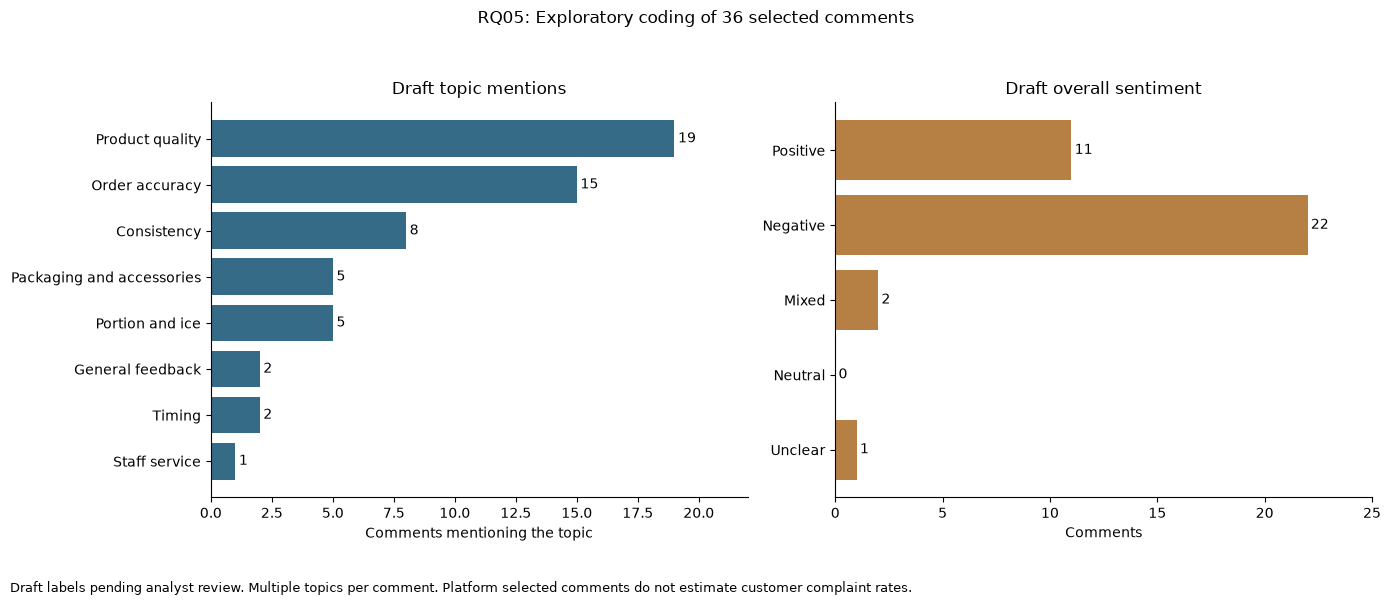

Topic shares can total more than 100 percent.
Sentiment applies to the whole comment, not each topic.
Cross branch comments retain their scope qualifications.
No hypothesis tests, brand rankings or files produced.


In [10]:
# 1. Confirm one coded record per collected comment.

if coded_reviews["review_id"].duplicated().any():
    raise ValueError("Repeated review IDs in coded_reviews.")

if coded_reviews["overall_sentiment"].isna().any():
    raise ValueError("Some comments have no proposed sentiment.")

if coded_reviews["topics"].isna().any():
    raise ValueError("Some comments have no proposed topics.")

number_of_comments = len(coded_reviews)


# 2. Count each topic once per comment.

review_topics = coded_reviews[
    [
        "review_id",
        "brand_name",
        "overall_sentiment",
        "topics",
        "coding_status",
    ]
].copy()

review_topics["topic"] = review_topics["topics"].str.split(";")

review_topics = review_topics.explode(
    "topic",
    ignore_index=True,
)

review_topics["topic"] = review_topics["topic"].str.strip()

review_topics = review_topics.drop_duplicates(
    subset=["review_id", "topic"]
)

topic_counts = (
    review_topics.groupby("topic")["review_id"]
    .nunique()
    .reindex(review_codebook["topic"], fill_value=0)
    .rename("comments_mentioning_topic")
    .reset_index()
)

topic_counts["denominator_comments"] = number_of_comments

topic_counts["sample_share_percent"] = (
    topic_counts["comments_mentioning_topic"]
    / number_of_comments
    * 100
).round(1)

topic_counts = topic_counts.sort_values(
    "comments_mentioning_topic",
    ascending=False,
)

print("Draft topic counts:")
display(topic_counts)


# 3. Count overall sentiment, retaining Mixed and Unclear.

sentiment_order = [
    "Positive",
    "Negative",
    "Mixed",
    "Neutral",
    "Unclear",
]

sentiment_counts = (
    coded_reviews["overall_sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
    .rename_axis("overall_sentiment")
    .reset_index(name="comments")
)

sentiment_counts["denominator_comments"] = number_of_comments

sentiment_counts["sample_share_percent"] = (
    sentiment_counts["comments"]
    / number_of_comments
    * 100
).round(1)

print("\nDraft overall sentiment counts:")
display(sentiment_counts)


# 4. Visualise the selected comments without ranking brands.

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

topic_chart = topic_counts.sort_values(
    "comments_mentioning_topic"
)

axes[0].barh(
    topic_chart["topic"],
    topic_chart["comments_mentioning_topic"],
    color="#356B87",
)

for position, count in enumerate(
    topic_chart["comments_mentioning_topic"]
):
    axes[0].text(count + 0.15, position, str(count), va="center")

axes[0].set_title("Draft topic mentions")
axes[0].set_xlabel("Comments mentioning the topic")
axes[0].set_xlim(
    0,
    int(topic_counts["comments_mentioning_topic"].max()) + 3,
)

axes[1].barh(
    sentiment_counts["overall_sentiment"],
    sentiment_counts["comments"],
    color="#B68045",
)

for position, count in enumerate(sentiment_counts["comments"]):
    axes[1].text(count + 0.15, position, str(count), va="center")

axes[1].set_title("Draft overall sentiment")
axes[1].set_xlabel("Comments")
axes[1].set_xlim(0, int(sentiment_counts["comments"].max()) + 3)
axes[1].invert_yaxis()

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    f"RQ05: Exploratory coding of {number_of_comments} selected comments"
)

fig.text(
    0.01,
    0.01,
    "Draft labels pending analyst review. Multiple topics per comment. "
    "Platform selected comments do not estimate customer complaint rates.",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

print("Topic shares can total more than 100 percent.")
print("Sentiment applies to the whole comment, not each topic.")
print("Cross branch comments retain their scope qualifications.")
print("No hypothesis tests, brand rankings or files produced.")

### RQ05 Preliminary Findings

Draft coding identifies product quality in 19 comments, order
accuracy in 15 and consistency in eight.

The proposed overall sentiment labels are 11 Positive, 22 Negative,
two Mixed and one Unclear.

Topic mentions include praise and criticism. Overall sentiment
cannot automatically be assigned to every topic within a comment.

### Business implication

The comments suggest issues worth investigating through operational
checks, including drink preparation, customisation instructions,
order completeness, portions and accessories.

Positive comments also identify experiences worth preserving,
including taste, accurate requests, packing and helpful service.

### Limitations

These findings describe 36 platform selected comments across
three brands. They are not representative complaint rates or
estimates of customer satisfaction.

The labels remain draft interpretations pending analyst review.
Some comments compare different branches or previous orders.

No brand ranking, causal conclusion or statistical significance
claim is supported. RQ05 remains partially answered.

## 6. Ordering and Delivery

### Research question

RQ06: How do ordering, pickup and delivery experiences compare?

### Purpose

Compare published channel descriptions, payment options and
documented ordering conditions.

### Evidence rules

Published features are company statements.
They do not establish successful checkout, current availability,
delivery coverage or actual waiting time.

Missing fees remain unknown rather than zero.
Payment processing or order holding periods are not service times.

In [11]:
# 1. Add brand names to the ordering observations.

ordering_analysis = datasets["ordering_channels"].merge(
    datasets["competitor_master"][["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)


# 2. Display the complete recorded channel descriptions.

print("RQ06: Published ordering and delivery evidence")

with pd.option_context("display.max_colwidth", None):
    display(
        ordering_analysis[
            [
                "channel_observation_id",
                "brand_name",
                "branch_id",
                "source_id",
                "observed_date",
                "channel",
                "ordering_mode",
                "location_scope",
                "access_method",
                "availability_status",
                "ordering_steps",
                "customization_options",
                "payment_options",
                "minimum_order_php",
                "delivery_fee_php",
                "other_fee_terms",
                "delivery_coverage",
                "quoted_wait_minutes",
                "checkout_verified",
                "notes",
            ]
        ].T
    )


# 3. Describe the availability of comparison inputs.

comparison_fields = [
    "branch_id",
    "ordering_steps",
    "customization_options",
    "payment_options",
    "minimum_order_php",
    "delivery_fee_php",
    "other_fee_terms",
    "delivery_coverage",
    "quoted_wait_minutes",
]

ordering_field_coverage = pd.DataFrame({
    "field": comparison_fields,
    "records_with_value": [
        int(ordering_analysis[field].notna().sum())
        for field in comparison_fields
    ],
})

ordering_field_coverage["total_records"] = len(ordering_analysis)

print("\nRecorded field coverage:")
display(ordering_field_coverage)

print("\nCheckout verification labels:")
display(
    ordering_analysis["checkout_verified"]
    .value_counts(dropna=False)
    .rename_axis("recorded_status")
    .reset_index(name="records")
)


# 4. Display primary source qualifications.

ordering_source_ids = (
    ordering_analysis["source_id"].dropna().unique()
)

print("\nPrimary source qualifications:")

with pd.option_context("display.max_colwidth", None):
    display(
        datasets["source_register"].loc[
            datasets["source_register"]["source_id"].isin(
                ordering_source_ids
            ),
            [
                "source_id",
                "source_title",
                "source_url",
                "published_date",
                "effective_date",
                "verification_status",
                "notes",
            ],
        ]
    )

print("\nOrdering observations:", len(ordering_analysis))
print("Brands represented:", ordering_analysis["brand_id"].nunique())
print("Populated text fields do not establish complete or verified mechanics.")
print("No channel scores, fee comparisons or files produced.")

RQ06: Published ordering and delivery evidence


,0,1,2,3,4
channel_observation_id,CHN0001,CHN0002,CHN0003,CHN0004,CHN0005
brand_name,ZUS Coffee,PICKUP COFFEE,"But First, Coffee",TOMORO COFFEE,PICKUP COFFEE
branch_id,<NA>,<NA>,<NA>,<NA>,<NA>
source_id,SRC0059,SRC0065,SRC0062,SRC0008,SRC0086
observed_date,2026-10-23 00:00:00,2026-10-23 00:00:00,2026-10-23 00:00:00,2026-10-23 00:00:00,2026-10-23 00:00:00
channel,ZUS App,PICKUP App,Official ordering website,TOMORO App,PICKUP App
ordering_mode,Unresolved,Order ahead for branch collection,Unresolved,Pickup and delivery described in terms,Pickup and delivery described in terms
location_scope,Philippine website; branch coverage unresolved,Philippine website; participating branches unresolved,Philippine website; participating branches unresolved,Philippine website terms; branch availability untested,Philippine website terms; participating branches unresolved
access_method,Official website description,Official website description,Official website outbound order link,Inspection of saved official application terms,Inspection of saved official application terms
availability_status,Published capability,Published capability,Published link,Published terms; operational availability unverified,Published terms; operational availability unverified



Recorded field coverage:


,field,records_with_value,total_records
0,branch_id,0,5
1,ordering_steps,3,5
2,customization_options,1,5
3,payment_options,2,5
4,minimum_order_php,0,5
5,delivery_fee_php,0,5
6,other_fee_terms,2,5
7,delivery_coverage,0,5
8,quoted_wait_minutes,0,5



Checkout verification labels:


,recorded_status,records
0,No,5



Primary source qualifications:


,source_id,source_title,source_url,published_date,effective_date,verification_status,notes
7,SRC0008,TOMORO COFFEE Philippine terms page,https://www.tomoro-coffee.ph/services,NaT,NaT,Verified,User supplied browser text inspected. Application provider statement and published ordering features supported. Features not tested. Store operator and franchise entity unresolved. Earlier HTML capture retained in its original capture folder.
58,SRC0059,ZUS Philippine rewards and app page,https://zuscoffee.ph/rewards/,NaT,NaT,Verified,"Selected inspected statements, not a full page capture. Verification concerns transcription accuracy. Publication and effective dates unresolved. No independent performance or checkout verification."
61,SRC0062,BFC published franchise formats and support,https://butfirstcoffee.ph/franchise/,NaT,NaT,Verified,"Selected inspected statements, not full page capture. Retrieved 2026-10-23. Effective dates unresolved unless specified. Verification concerns transcription accuracy, not performance."
64,SRC0065,PICKUP official app capabilities,https://pickup-coffee.com/pickup-app,NaT,NaT,Verified,"Selected inspected statements, not full page capture. Retrieved 2026-10-23. Effective dates unresolved unless specified. Verification concerns transcription accuracy, not performance."
85,SRC0086,PICKUP general voucher terms inspected,https://pickup-coffee.com/terms-conditions,NaT,NaT,Verified,General voucher conditions inspected. Specific voucher validity and usage conditions remain offer dependent. No numeric points earning rate or general points expiry established from these passages.



Ordering observations: 5
Brands represented: 4
Populated text fields do not establish complete or verified mechanics.
No channel scores, fee comparisons or files produced.


### RQ06 Findings

The October 23 baseline contains five ordering observations across
four brands. These describe published capabilities or terms.
No checkout journey was verified.

The complete prepared dataset contains six observations. The additional
BFC app observation belongs to the October 25 supplementary review.
Its relationship to the captured app launching soon message remains
unresolved.

### Business implication

The published procedures provide a reference for reviewing BFC's
ordering information, including branch selection, customisation,
payment choices, confirmation and cancellation terms.

The evidence cannot establish which channel is cheaper, faster
or easier to use.

### Limitations

PICKUP's 20 minute collection holding period is not a preparation
or delivery time.

Refund credits do not establish a loyalty earning rate.
Missing fees are unknown rather than zero.

No channel ranking or service performance claim is reported.
RQ06 remains partially answered.

### Source references

BFC: SRC0062.
ZUS: SRC0059, with qualifications in SRC0085.
PICKUP: SRC0065 and SRC0086.
TOMORO: SRC0008.

## 7. Recorded Branch Coverage

### Research question

RQ07: Where have verified branch networks and formats changed?

### Purpose

Describe the locations, verification status and geographic coverage
of the collected branch directory.

### Limitations

The directory contains selected listings and provisional entries.
It does not establish national network size or historical changes.

Possible aliases remain unresolved. Missing geography and formats
will not be inferred from branch names.

Listed locations are not automatically confirmed operating outlets.

In [12]:
# 1. Add brand names to the directory.

branch_analysis = datasets["branch_directory"].merge(
    datasets["competitor_master"][["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)

print("Recorded branch entries:")
display(
    branch_analysis[
        [
            "branch_id",
            "brand_name",
            "branch_name",
            "city",
            "island_group",
            "store_format",
            "operating_status",
            "verification_status",
            "source_ids",
        ]
    ]
)


# 2. Describe verification and operating status separately.

print("\nVerification status:")
display(
    branch_analysis["verification_status"]
    .value_counts(dropna=False)
    .rename_axis("verification_status")
    .reset_index(name="directory_entries")
)

print("\nRecorded operating status:")
with pd.option_context("display.max_colwidth", None):
    display(
        branch_analysis["operating_status"]
        .value_counts(dropna=False)
        .rename_axis("operating_status")
        .reset_index(name="directory_entries")
    )


# 3. Describe recorded geography without inferring missing values.

geography_fields = [
    "address",
    "city",
    "province",
    "region",
    "island_group",
    "store_format",
    "status_date",
]

branch_field_coverage = pd.DataFrame({
    "field": geography_fields,
    "records_with_value": [
        int(branch_analysis[field].notna().sum())
        for field in geography_fields
    ],
})

branch_field_coverage["total_entries"] = len(branch_analysis)

print("\nBranch field coverage:")
display(branch_field_coverage)

print("\nRecorded island groups:")
display(
    branch_analysis["island_group"]
    .fillna("Not recorded")
    .value_counts()
    .rename_axis("island_group")
    .reset_index(name="directory_entries")
)


# 4. Inspect previously identified identity questions.

identity_review_ids = [
    "BRN0001",
    "BRN0008",
    "BRN0019",
]

print("\nEntries requiring identity review:")

with pd.option_context("display.max_colwidth", None):
    display(
        branch_analysis.loc[
            branch_analysis["branch_id"].isin(identity_review_ids),
            [
                "branch_id",
                "brand_name",
                "branch_name",
                "address",
                "verification_status",
                "source_ids",
                "notes",
            ],
        ]
    )


# 5. Report the limits of branch linkage.

menu = datasets["menu_pricing"]

print("\nDirectory entries:", len(branch_analysis))
print("Brands represented:", branch_analysis["brand_id"].nunique())
print("Menu records with branch IDs:", int(menu["branch_id"].notna().sum()))
print("Menu records without branch IDs:", int(menu["branch_id"].isna().sum()))
print("No aliases merged or branch IDs assigned.")
print("No national network totals or historical changes calculated.")
print("No files changed.")

Recorded branch entries:


,branch_id,brand_name,branch_name,city,island_group,store_format,operating_status,verification_status,source_ids
0,BRN0001,Macao Imperial Tea,SM City North EDSA,Quezon City,Luzon,<NA>,Listed; current operation unconfirmed,Partial,SRC0077
1,BRN0002,Macao Imperial Tea,Ayala Center Cebu,Cebu City,Visayas,<NA>,Listed; current operation unconfirmed,Partial,SRC0077
2,BRN0003,Macao Imperial Tea,SM City Davao,Davao City,Mindanao,<NA>,Listed; current operation unconfirmed,Partial,SRC0077
3,BRN0004,ZUS Coffee,University Mall Taft,Manila,Luzon,<NA>,Listed; current operation unconfirmed,Partial,SRC0078
4,BRN0005,PICKUP COFFEE,Lifestyle Strip,Santo Tomas,Luzon,<NA>,Listed; current operation unconfirmed,Partial,SRC0079
5,BRN0006,Juan Café,"LMG Building, Quezon City",<NA>,<NA>,<NA>,Pricing listing only; current operation unconf...,Partial,SRC0042
6,BRN0007,TOMORO COFFEE,"Padilla Ortigas, Pasig City",<NA>,<NA>,<NA>,Pricing listing only; current operation unconf...,Pending,SRC0045
7,BRN0008,Macao Imperial Tea,"SM North Main, Quezon City",<NA>,<NA>,<NA>,Pricing listing only; current operation unconf...,Pending,SRC0047
8,BRN0009,Black Scoop Cafe,"The Gardenwalk, Cainta",<NA>,<NA>,<NA>,Pricing listing only; current operation unconf...,Pending,SRC0044
9,BRN0010,Kurimi Milk Tea Bar,"Catalunan Pequeño, Davao City",<NA>,<NA>,<NA>,Pricing listing only; current operation unconf...,Pending,SRC0051



Verification status:


,verification_status,directory_entries
0,Pending,13
1,Partial,11



Recorded operating status:


...


Recorded island groups:


,island_group,directory_entries
0,Not recorded,18
1,Luzon,4
2,Visayas,1
3,Mindanao,1



Entries requiring identity review:


,branch_id,brand_name,branch_name,address,verification_status,source_ids,notes
0,BRN0001,Macao Imperial Tea,SM City North EDSA,"CC 139 SM City North EDSA, North Ave Corner Bagong Pag-asa 1",Partial,SRC0077,Name and address transcribed from official directory. Island group assigned using directory geography. Store format and current operation not independently confirmed. Province and region left for geographic standardization. Match to earlier SM North Main Foodpanda listing unresolved.
7,BRN0008,Macao Imperial Tea,"SM North Main, Quezon City",<NA>,Pending,SRC0047,"Provisional entry derived from menu location_scope. Label retained as recorded, not an independently verified branch name. Check for aliases of existing branches before assigning menu branch IDs. Address, geography, format, and operation unresolved."
18,BRN0019,BigBrew,"Plaza Paco listing, Manila",1386 Burgos Pandacan Manila Metro Manila HXMX+RM,Pending,SRC0043,"Provisional entry derived from menu location_scope. Label retained as recorded, not an independently verified branch name. Check for aliases of existing branches before assigning menu branch IDs. Address, geography, format, and operation unresolved. | Foodpanda listing title states BigBrew Plaza Paco, while its displayed address states Pandacan. Address retained as a platform statement. Branch identity requires independent confirmation. Do not assign menu branch IDs from this statement alone."



Directory entries: 24
Brands represented: 21
Menu records with branch IDs: 0
Menu records without branch IDs: 131
No aliases merged or branch IDs assigned.
No national network totals or historical changes calculated.
No files changed.


### RQ07 Findings

The directory contains 24 entries across 21 brands.
Thirteen entries are Pending and eleven are partially verified.

Twelve entries contain addresses. Six contain city and island group
information. None has a recorded store format or operating status date.

All 129 menu observations lack assigned branch IDs. Some have named
location scopes, but these have not been reconciled to the directory.

### Identity qualifications

BRN0001 and BRN0008 may describe the same Macao Imperial Tea outlet.
They remain separate pending confirmation.

BigBrew BRN0019 has a Plaza Paco listing label and a Pandacan address.
Its identity remains unresolved.

### Business implication

The directory provides a starting list for location verification.
It does not support territory prioritisation, network rankings,
market share estimates or expansion claims.

### Limitations

Recorded island groups describe only six entries and cannot establish
the geographic distribution of the full sample.

No branch openings, closures or format changes have been verified.
RQ07 remains partially answered.

## 8. Published Franchise Offers

### Research question

RQ08: How do equivalent franchise offers compare?

### Purpose

Describe recorded formats, financial terms, inclusions and support.

### Comparison rules

A franchise fee is not total opening investment.
An advertised starting package cost is not a complete quotation.

Inquiry pages do not establish complete package terms.
Missing fees are unknown rather than zero.

Compare financial offers only when format, scope, inclusions,
exclusions, tax treatment and effective dates are sufficiently aligned.

Company payback and profitability claims are not verified outcomes.

In [13]:
# 1. Add brand names to the franchise records.

franchise_analysis = datasets["franchise_offers"].merge(
    datasets["competitor_master"][["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)


# 2. Inspect financial values without combining different cost bases.

print("RQ08: Published formats and financial fields")

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(
        franchise_analysis[
            [
                "package_version_id",
                "brand_name",
                "package_name",
                "market_scope",
                "store_format",
                "currency",
                "franchise_fee",
                "advertised_package_start_php",
                "total_investment_min",
                "total_investment_max",
                "tax_basis",
                "effective_date",
                "availability_status",
                "source_id",
            ]
        ]
    )


# 3. Inspect support and agreement qualifications for every record.

print("\nPublished terms and support:")

for row_index, row in franchise_analysis.iterrows():
    print(
        "\n",
        row["package_version_id"],
        row["brand_name"],
        row["package_name"],
    )

    with pd.option_context("display.max_colwidth", None):
        display(
            row[
                [
                    "investment_inclusions",
                    "investment_exclusions",
                    "royalty_terms",
                    "marketing_fee_terms",
                    "other_recurring_fees",
                    "agreement_term",
                    "renewal_terms",
                    "space_requirements",
                    "training_support",
                    "operational_support",
                    "supply_obligations",
                    "notes",
                ]
            ].to_frame(name="recorded_statement")
        )


# 4. Report field coverage.
# Populated text may still contain unresolved terms.

franchise_fields = [
    "store_format",
    "franchise_fee",
    "advertised_package_start_php",
    "total_investment_min",
    "total_investment_max",
    "investment_inclusions",
    "investment_exclusions",
    "tax_basis",
    "royalty_terms",
    "marketing_fee_terms",
    "other_recurring_fees",
    "agreement_term",
    "renewal_terms",
    "training_support",
    "operational_support",
    "supply_obligations",
    "effective_date",
]

franchise_field_coverage = pd.DataFrame({
    "field": franchise_fields,
    "records_with_value": [
        int(franchise_analysis[field].notna().sum())
        for field in franchise_fields
    ],
})

franchise_field_coverage["total_records"] = len(franchise_analysis)

print("\nFranchise field coverage:")
display(franchise_field_coverage)

print("Records:", len(franchise_analysis))
print("Brands represented:", franchise_analysis["brand_id"].nunique())
print("No investment averages, affordability rankings or returns calculated.")
print("No files changed.")

RQ08: Published formats and financial fields


,package_version_id,brand_name,package_name,market_scope,store_format,currency,franchise_fee,advertised_package_start_php,total_investment_min,total_investment_max,tax_basis,effective_date,availability_status,source_id
0,FRN0001,Potato Corner,Philippine FAQ terms; package format unspecified,Philippines,<NA>,PHP,150000.0,<NA>,<NA>,<NA>,<NA>,NaT,Published inquiry; site approval required,SRC0060
1,FRN0002,"But First, Coffee",Published franchise format overview,Philippines,Inline store; kiosk; trailer,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Published inquiry,SRC0062
2,FRN0003,Coffee First,Published franchise support overview,Philippines,<NA>,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Inquiry subject to approval,SRC0067
3,FRN0004,Bo's Coffee,Published Philippine franchise overview,Philippines,<NA>,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Published Philippine inquiry,SRC0068
4,FRN0005,Moonleaf,Published franchise format overview,Philippines,Kiosk; Cafe,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Published inquiry,SRC0069
5,FRN0006,Chatime,Philippine franchise inquiry only,Philippines,<NA>,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Published inquiry form,SRC0070
6,FRN0007,PICKUP COFFEE,Published franchise overview,Philippines,Cafe; Cart; Kiosk,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Published inquiry,SRC0071
7,FRN0008,Juan Café,Published franchise fee statements,Philippines,<NA>,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Published franchise promotion,SRC0072
8,FRN0009,Macao Imperial Tea,Brand link to group franchise inquiry,Philippines,<NA>,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Published group inquiry route,SRC0073
9,FRN0010,BigBrew,Homepage franchise promotion,Philippines,<NA>,PHP,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,Promotion published; details unresolved,SRC0075



Published terms and support:

 FRN0001 Potato Corner Philippine FAQ terms; package format unspecified


,recorded_statement
investment_inclusions,<NA>
investment_exclusions,<NA>
royalty_terms,Company states no royalty fees
marketing_fee_terms,<NA>
other_recurring_fees,<NA>
agreement_term,<NA>
renewal_terms,50 percent of current franchise fee; FAQ illustration PHP 75000 for another five years
space_requirements,At least 6 square meters; frontage at least 2 meters
training_support,<NA>
operational_support,Company assesses applicant proposed location



 FRN0002 But First, Coffee Published franchise format overview


...


 FRN0015 Famous Belgian Waffles Inline advertised package starting cost


,recorded_statement
investment_inclusions,"Page lists trademark use, starter inventory, operating system, training, lease assistance and opening support. Format specific quotation confirmation required."
investment_exclusions,<NA>
royalty_terms,<NA>
marketing_fee_terms,<NA>
other_recurring_fees,<NA>
agreement_term,Three years; subject to renewal
renewal_terms,Renewal permitted; fees and conditions unresolved
space_requirements,12 square meters and above
training_support,Initial crew training and orientation
operational_support,"Lease assistance, opening support and ongoing marketing. Page states opening assistance three days after opening; duration and schedule require clarification."



Franchise field coverage:


,field,records_with_value,total_records
0,store_format,8,15
1,franchise_fee,1,15
2,advertised_package_start_php,5,15
3,total_investment_min,0,15
4,total_investment_max,0,15
5,investment_inclusions,5,15
6,investment_exclusions,0,15
7,tax_basis,0,15
8,royalty_terms,2,15
9,marketing_fee_terms,0,15


Records: 15
Brands represented: 11
No investment averages, affordability rankings or returns calculated.
No files changed.


### RQ08 Findings

The dataset contains 15 records across 11 brands, combining
franchise overviews, inquiry routes and selected financial statements.

Potato Corner publishes a PHP 150,000 franchise fee.
Famous Belgian Waffles publishes starting package costs for five
formats, ranging from PHP 580,000 to PHP 980,000.

These amounts have different cost definitions and cannot be
compared directly as total opening investment.

Published support includes training, site assistance, operations,
marketing, supply and technology, with different levels of detail.

### Business implication

The evidence provides a checklist for reviewing BFC's franchise
information and preparing comparable quotations.

BFC's recorded overview describes support but does not contain
a priced package. Its competitiveness cannot be assessed from
the current financial fields.

### Limitations

Total investment, exclusions, tax basis, marketing fees and other
recurring fees remain missing across all records.

Published no royalty or no renewal fee statements do not establish
the absence of other costs.

Five Famous Belgian Waffles formats share one source. They are
not independent evidence of market pricing.

No affordability ranking, expected return or payback comparison
is reported. RQ08 remains partially answered.

### Source references

Potato Corner: SRC0060.
BFC: SRC0062.
Other franchise records: their recorded source_id values.
Famous Belgian Waffles: SRC0088.

## 9. Other Commercial Offers

### Research question

RQ09: What additional commercial offers are competitors developing?

### Purpose

Describe documented event, corporate and other commercial offers.

### Comparison rules

Keep advertised prices separate from actual sales and costs.
Do not assume pax equals included cups.

Compare packages only when quantities, service methods, duration,
inclusions and additional charges are sufficiently aligned.

A published offer does not establish a new launch during 2026.
Unresolved Philippine applicability remains qualified.

RQ09: Recorded commercial offers

 DEV0001 Famous Belgian Waffles


,recorded_statement
offer_name,Famous Belgian Waffles Cafe
development_type,Published store format
description,Coffee shop style waffle offering with dining space
target_customer,Company describes social meetings and solo visits
channel,Physical cafe format
location_scope,Branch coverage unresolved
commercial_terms,<NA>
published_date,NaT
effective_date,NaT
source_id,SRC0061



 DEV0002 But First, Coffee


,recorded_statement
offer_name,Coffee catering and event carts
development_type,Published event service
description,Coffee services for celebrations and business events
target_customer,"Wedding, birthday, corporate, activation, and private event clients"
channel,Event inquiry
location_scope,Philippine website; participating branches unresolved
commercial_terms,<NA>
published_date,NaT
effective_date,NaT
source_id,SRC0063



 DEV0003 Moonleaf


...

,recorded_statement
offer_name,Party service and booking conditions
development_type,Published commercial offer
description,Official party page publishes a maximum service duration of four hours.
target_customer,Event organizers and private or corporate clients
channel,Official website
location_scope,Metro Manila and outside Metro Manila referenced; actual coverage requires confirmation
commercial_terms,Published transportation charges: PHP 2000 within Metro Manila; PHP 3000 outside Metro Manila. Full payment one week before the event. Cash or checks accepted. Page states no refund for cancellation by the client.
published_date,NaT
effective_date,NaT
source_id,SRC0092



Published event package variants:


,event_package_id,brand_name,package_name,service_method,pax,included_cups,cup_size_label,service_hours,advertised_price_php,source_id,source_page
0,EVT0001,"But First, Coffee",Signature Bar,Brewed,50,<NA>,12oz,4.0,7500.0,SRC0089,9
1,EVT0002,"But First, Coffee",Signature Bar,Brewed,100,<NA>,12oz,4.0,12000.0,SRC0089,9
2,EVT0003,"But First, Coffee",Signature Bar,Brewed,150,<NA>,12oz,4.0,17500.0,SRC0089,9
3,EVT0004,"But First, Coffee",Signature Bar,Espresso,50,<NA>,12oz,4.0,8500.0,SRC0089,9
4,EVT0005,"But First, Coffee",Signature Bar,Espresso,100,<NA>,12oz,4.0,13000.0,SRC0089,9
5,EVT0006,"But First, Coffee",Signature Bar,Espresso,150,<NA>,12oz,4.0,19000.0,SRC0089,9
6,EVT0007,"But First, Coffee",Matcha Bar,Brewed,50,<NA>,12oz,4.0,8000.0,SRC0089,11
7,EVT0008,"But First, Coffee",Matcha Bar,Brewed,100,<NA>,12oz,4.0,12500.0,SRC0089,11
8,EVT0009,"But First, Coffee",Matcha Bar,Brewed,150,<NA>,12oz,4.0,18500.0,SRC0089,11
9,EVT0010,"But First, Coffee",Matcha Bar,Espresso,50,<NA>,12oz,4.0,9000.0,SRC0089,11



Package conditions:


,package_name,service_method,tax_wording,location_scope,inclusions,additional_costs,effective_date,notes
0,Signature Bar,Brewed,Prices are subject to 12% Tax,Service area requires confirmation,"Deck describes event cart setup, baristas, personalized menu, claiming stubs and personalized decoration. Confirm applicability in the client quotation.",Location dependent logistics and selected extras require confirmation.,NaT,"Published package price, not a completed quotation. PAX is not assumed to equal included cups. 12oz is a cup label, not verified beverage volume. Effective date, availability and booking conditions unresolved. Four hour service description appears on PDF pages 5 and 6; cup labels appear on pages 8 and 10. For 200 PAX or more, the deck directs clients to inquire."
3,Signature Bar,Espresso,Prices are subject to 12% Tax,Service area requires confirmation,"Deck describes event cart setup, baristas, personalized menu, claiming stubs and personalized decoration. Confirm applicability in the client quotation.",Location dependent logistics and selected extras require confirmation.,NaT,"Published package price, not a completed quotation. PAX is not assumed to equal included cups. 12oz is a cup label, not verified beverage volume. Effective date, availability and booking conditions unresolved. Four hour service description appears on PDF pages 5 and 6; cup labels appear on pages 8 and 10. For 200 PAX or more, the deck directs clients to inquire."
6,Matcha Bar,Brewed,Prices are subject to 12% Tax,Service area requires confirmation,"Deck describes event cart setup, baristas, personalized menu, claiming stubs and personalized decoration. Confirm applicability in the client quotation.",Location dependent logistics and selected extras require confirmation.,NaT,"Published package price, not a completed quotation. PAX is not assumed to equal included cups. 12oz is a cup label, not verified beverage volume. Effective date, availability and booking conditions unresolved. Four hour service description appears on PDF pages 5 and 6; cup labels appear on pages 8 and 10. For 200 PAX or more, the deck directs clients to inquire."
9,Matcha Bar,Espresso,Prices are subject to 12% Tax,Service area requires confirmation,"Deck describes event cart setup, baristas, personalized menu, claiming stubs and personalized decoration. Confirm applicability in the client quotation.",Location dependent logistics and selected extras require confirmation.,NaT,"Published package price, not a completed quotation. PAX is not assumed to equal included cups. 12oz is a cup label, not verified beverage volume. Effective date, availability and booking conditions unresolved. Four hour service description appears on PDF pages 5 and 6; cup labels appear on pages 8 and 10. For 200 PAX or more, the deck directs clients to inquire."


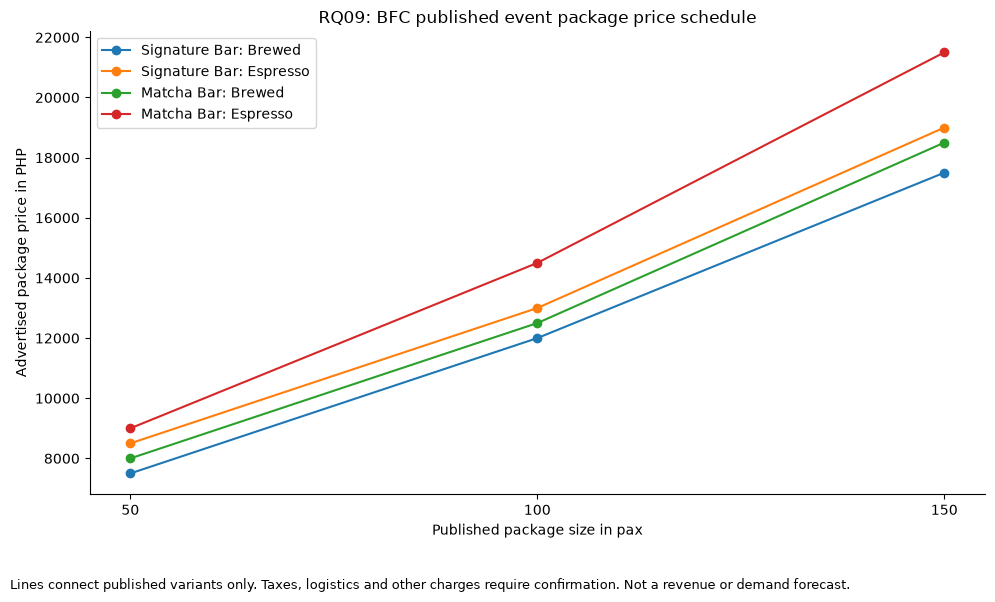

Commercial observations: 7
Brands with commercial observations: 6
Event package variants: 12
Brands with event package prices: 1
No per cup prices, final quotations or profitability calculated.
No files changed.


In [14]:
# 1. Add brand names to commercial observations and event packages.

brand_names = datasets["competitor_master"][
    ["brand_id", "brand_name"]
]

commercial_analysis = datasets["commercial_developments"].merge(
    brand_names,
    on="brand_id",
    how="left",
    validate="many_to_one",
)

event_analysis = datasets["event_packages"].merge(
    brand_names,
    on="brand_id",
    how="left",
    validate="many_to_one",
)


# 2. Inspect the commercial offers and their qualifications.

print("RQ09: Recorded commercial offers")

for row_index, row in commercial_analysis.iterrows():
    print("\n", row["development_id"], row["brand_name"])

    with pd.option_context("display.max_colwidth", None):
        display(
            row[
                [
                    "offer_name",
                    "development_type",
                    "description",
                    "target_customer",
                    "channel",
                    "location_scope",
                    "commercial_terms",
                    "published_date",
                    "effective_date",
                    "source_id",
                    "notes",
                ]
            ].to_frame(name="recorded_statement")
        )


# 3. Inspect event package prices and conditions.

print("\nPublished event package variants:")

display(
    event_analysis[
        [
            "event_package_id",
            "brand_name",
            "package_name",
            "service_method",
            "pax",
            "included_cups",
            "cup_size_label",
            "service_hours",
            "advertised_price_php",
            "source_id",
            "source_page",
        ]
    ]
)

print("\nPackage conditions:")
with pd.option_context("display.max_colwidth", None):
    display(
        event_analysis[
            [
                "package_name",
                "service_method",
                "tax_wording",
                "location_scope",
                "inclusions",
                "additional_costs",
                "effective_date",
                "notes",
            ]
        ].drop_duplicates()
    )


# 4. Plot the published BFC package price schedule.
# Pax is the published package label, not a verified cup quantity.

bfc_events = event_analysis.loc[
    event_analysis["brand_id"].eq("BFC001")
    & event_analysis["pax"].notna()
    & event_analysis["advertised_price_php"].notna()
].copy()

event_keys = ["package_name", "service_method", "pax"]

if bfc_events.duplicated(event_keys).any():
    raise ValueError("Multiple prices found for a selected package variant.")

fig, ax = plt.subplots(figsize=(10, 6))

for package_name in bfc_events["package_name"].drop_duplicates():
    package_rows = bfc_events.loc[
        bfc_events["package_name"].eq(package_name)
    ]

    for service_method in package_rows["service_method"].drop_duplicates():
        chart_data = package_rows.loc[
            package_rows["service_method"].eq(service_method)
        ].sort_values("pax")

        ax.plot(
            chart_data["pax"].astype(float),
            chart_data["advertised_price_php"].astype(float),
            marker="o",
            label=f"{package_name}: {service_method}",
        )

ax.set_xticks(sorted(bfc_events["pax"].unique()))
ax.set_xlabel("Published package size in pax")
ax.set_ylabel("Advertised package price in PHP")
ax.set_title("RQ09: BFC published event package price schedule")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.01,
    0.01,
    "Lines connect published variants only. Taxes, logistics and other charges "
    "require confirmation. Not a revenue or demand forecast.",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

print("Commercial observations:", len(commercial_analysis))
print("Brands with commercial observations:", commercial_analysis["brand_id"].nunique())
print("Event package variants:", len(event_analysis))
print("Brands with event package prices:", event_analysis["brand_id"].nunique())
print("No per cup prices, final quotations or profitability calculated.")
print("No files changed.")

### RQ09 Findings

Seven commercial observations cover six brands.

BFC has 12 published event package variants across Signature Bar
and Matcha Bar, with brewed and espresso service options.

Advertised prices range from PHP 7,500 to PHP 21,500 for packages
labelled 50, 100 and 150 pax. The deck describes four hours of
service and states that prices are subject to 12 percent tax.

PICKUP publishes an event inquiry route. Gong cha publishes
service duration, transport charges and booking conditions.
Equivalent competitor package prices remain unavailable.

### Business implication

BFC's published package structure provides a starting point for
sales quotations. Quotations should clarify included cups, service
coverage, logistics, tax treatment, extras and booking conditions.

Competitor offer descriptions identify services worth investigating.
They do not establish an unmet market opportunity or expected demand.

### Limitations

Pax does not establish included cup quantity.
Advertised prices are not final quotations, revenue or profit.

ZUS service applicability in the Philippines remains unresolved.
Published offers are not automatically new developments in 2026.

No competitor price ranking or profitability conclusion is reported.
RQ09 remains partially answered.

### Source references

BFC: SRC0063 and SRC0089.
PICKUP: SRC0091.
Gong cha: SRC0092.
ZUS: SRC0090.
Moonleaf: SRC0069.
Famous Belgian Waffles: SRC0061.

## 10. Historical Evidence and Baseline

### Research question

RQ10: What historical changes can be verified, and which measures
should BFC track against the 2026 baseline?

### Purpose

Review source dates, price rechecks and operating history qualifications.

### Evidence rules

Collection date, publication date and effective date have different meanings.

A historical article does not automatically provide a comparable
historical observation.

Different retrieved prices do not establish a price change unless
product, serving, branch, channel, conditions and periods are aligned.

The original 2024 competitor review remains unavailable.
Missing historical evidence will not be reconstructed from assumptions.

### Future monitoring

Track matched product prices, offer conditions, loyalty rules,
verified branch status, franchise package versions and commercial
offer terms using stable identifiers and dated evidence.

In [15]:
# 1. Review source date coverage.

sources = datasets["source_register"]

source_date_rows = []

for field in ["published_date", "effective_date", "collected_date"]:
    source_date_rows.append({
        "date_field": field,
        "records_with_date": int(sources[field].notna().sum()),
        "records_without_date": int(sources[field].isna().sum()),
        "total_sources": len(sources),
    })

print("RQ10: Source date coverage")
display(pd.DataFrame(source_date_rows))


# 2. Inspect dated source records.
# Publication dates do not independently establish effective dates.

print("\nSources with recorded publication dates:")

with pd.option_context("display.max_colwidth", None):
    display(
        sources.loc[
            sources["published_date"].notna(),
            [
                "source_id",
                "brand_id",
                "source_title",
                "published_date",
                "effective_date",
                "collected_date",
                "historical_period",
                "notes",
            ],
        ].sort_values("published_date")
    )


# 3. Describe when the menu observations were collected.

menu = datasets["menu_pricing"]

print("\nMenu observation dates:")
display(
    menu.groupby("observed_date", dropna=False)
    .agg(
        records=("observation_id", "size"),
        sources=("source_id", "nunique"),
        brands=("brand_id", "nunique"),
    )
    .reset_index()
)


# 4. Review the saved price recheck findings.

recheck_path = references_path / "price_recheck_summary.csv"

if recheck_path.is_file():
    price_recheck_summary = pd.read_csv(
        recheck_path,
        dtype="string",
    )

    print("\nRecorded price recheck findings:")
    with pd.option_context("display.max_colwidth", None):
        display(price_recheck_summary)
else:
    print("\nPrice recheck summary not found.")
    print("No conclusions about those rechecks are added.")


# 5. Bring operating history qualifications into Notebook 04.
# Use the saved baseline audit rather than today's date.

history_path = references_path / "operating_year_audit.csv"

if history_path.is_file():
    operating_year_audit = pd.read_csv(
        history_path,
        dtype="string",
    )

    print("\nRecorded operating history:")
    display(
        operating_year_audit[
            [
                "brand_id",
                "brand_name",
                "baseline_date",
                "ph_start_year",
                "age_min_years",
                "age_max_years",
                "age_group",
            ]
        ]
    )

    print("\nBFC and TOMO history qualifications:")
    with pd.option_context("display.max_colwidth", None):
        display(
            operating_year_audit.loc[
                operating_year_audit["brand_id"].isin(
                    ["BFC001", "BFC004"]
                ),
                [
                    "brand_name",
                    "age_basis",
                    "evidence_qualification",
                ],
            ]
        )
else:
    print("\nOperating year audit not found.")
    print("No operating ages calculated.")


print("\nStudy baseline:", baseline_date.date())
print("No historical price change percentages calculated.")
print("Founding histories are not evidence of historical price changes.")
print("No files changed.")

RQ10: Source date coverage


,date_field,records_with_date,records_without_date,total_sources
0,published_date,7,133,140
1,effective_date,0,140,140
2,collected_date,139,1,140



Sources with recorded publication dates:


,source_id,brand_id,source_title,published_date,effective_date,collected_date,historical_period,notes
107,SRC0108,BFC012,Farron Cafe first Philippine food cart history,2020-03-02,NaT,2026-10-23,Historical origin,The Philippine Star reports the first Farron Cafe food cart opened beside UE Manila in February 2010. This records operating history rather than incorporation or franchising.
99,SRC0100,BFC009,Dunkin Philippine operating history from Inspire Brands,2023-08-15,NaT,2026-10-23,Historical,Inspire Brands states that Dunkin has served Filipino customers since 1981. Supports Philippine start year 1981. The article's 800 location milestone relates to 2023 and is not a current branch count.
103,SRC0104,BFC003,Juan Cafe first Philippine branch history,2023-09-16,NaT,2026-10-23,Historical origin,"GMA's September 16, 2023 report says the first Juan Cafe branch opened the previous November. November 2022 is derived from that dated report and agrees with the official brand creation year. Exact opening day is unresolved."
97,SRC0098,BFC001,BFC Philippine operating origins in dated industry reporting,2024-03-27,NaT,2026-10-23,Historical,"World Coffee Portal reports BFC began as an online ready-to-drink coffee business in August 2020, opened its first physical store in November 2020 and began franchising in 2021. Philippine start year uses first commercial operations, including online operations. Store counts and expansion plans in this 2024 article are not treated as current observations."
102,SRC0103,BFC021,ZUS Philippine debut confirmed in dated industry reporting,2024-04-22,NaT,2026-10-23,Historical,"April 22, 2024 reporting confirms ZUS debuted in Quezon City in September 2023. Philippine start year is 2023. Malaysian founding milestones are separate. Historical store counts and expansion targets are not current observations."
101,SRC0102,BFC005,TOMORO first Philippine operations in dated reporting,2024-06-15,NaT,2026-10-23,Historical,"June 15, 2024 reporting states that TOMORO opened its first wave of Philippine stores in April 2024, followed by its Manila flagship opening on June 13, 2024. Philippine start year is 2024. Flagship opening is not treated as the first Philippine operating date. Historical expansion targets and franchise offers are not accepted as current terms."
123,SRC0124,BFC001,BPI announcement of BFC and VYBE promotions,2026-08-10,NaT,2026-10-25,2026 historical promotion,Retrieved after baseline. Announcement supplies historical validity periods. No redemption or performance test.



Menu observation dates:


...


Recorded operating history:


,brand_id,brand_name,baseline_date,ph_start_year,age_min_years,age_max_years,age_group
0,BFC001,"But First, Coffee",2026-10-23,2020,6,6,6 to 10 years
1,BFC002,PICKUP COFFEE,2026-10-23,2022,3,4,1 to 5 years
2,BFC003,Juan Café,2026-10-23,2022,3,4,1 to 5 years
3,BFC004,TOMO Coffee,2026-10-23,2022,3,4,Provisional: 1 to 5 years
4,BFC005,TOMORO COFFEE,2026-10-23,2024,1,2,1 to 5 years
5,BFC006,Macao Imperial Tea,2026-10-23,2017,8,9,6 to 10 years
6,BFC007,Black Scoop Cafe,2026-10-23,2018,7,8,6 to 10 years
7,BFC008,Kurimi Milk Tea Bar,2026-10-23,2019,6,7,6 to 10 years
8,BFC009,Dunkin',2026-10-23,1981,44,45,More than 10 years
9,BFC010,Figaro Coffee,2026-10-23,1993,32,33,More than 10 years



BFC and TOMO history qualifications:


,brand_name,age_basis,evidence_qualification
0,"But First, Coffee","Online Philippine operations began August 2020; six completed years at October 23, 2026",SRC0098 distinguishes online operations in August 2020 from the first physical store in November 2020. Physical store history is five completed years at the baseline. Exact opening days remain unspecified.
3,TOMO Coffee,Reported Philippine founding year; first store opening unconfirmed,2022 reported founding year conflicts with an earlier official website statement of 2021



Study baseline: 2026-10-23
No historical price change percentages calculated.
Founding histories are not evidence of historical price changes.
No files changed.


### RQ10 Findings

The menu dataset contains 129 observations from 32 sources across
21 brands, all recorded on October 23, 2026.

Price rechecks reveal differences between retrieved versions.
They do not establish chronological price changes.

Chatime's promotional and recheck prices have unresolved conditions.
Moonleaf's product identity and serving equivalence remain unresolved.
Matching Gong cha starting prices do not establish checkout prices.

Philippine start years are recorded for all 23 brands.
Most operating ages remain ranges because exact opening dates
are unavailable. TOMO's founding year remains qualified.

BFC's online operations and first physical store are documented
as separate milestones.

### Business implication

The collected evidence provides a qualified starting point for
future monitoring. Comparisons should preserve product, size,
temperature, channel, branch and offer conditions.

### Limitations

The original 2024 review remains unavailable.
Founding histories do not establish changes in prices, branch
networks, franchise terms or commercial offers.

No historical price increase, expansion rate or change in customer
sentiment is established. RQ10 remains partially answered.

## 11. Price Distribution and Outlier Assessment

### Research question alignment

RQ01: Pricing and value.

### Purpose

Assess whether comparable price groups support meaningful
distribution and outlier analysis.

### Method

Set aside missing prices, unresolved serving details, promotional
prices, starting prices and observations flagged for repeat review.

Keep brands, products, temperatures, cup labels, channels and
recorded location scopes separate.

### Interpretation

Small groups cannot establish a distribution shape.
Repeated captures do not increase the number of independent prices.

No values will be removed automatically. Passing an outlier screen
would not establish that prices are current or comparable.

In [16]:
# 1. Identify records suitable for an initial price structure check.

menu = datasets["menu_pricing"].copy()

repeat_review_ids = cleaning_review.loc[
    cleaning_review["dataset"].eq("menu_pricing"),
    "record_id",
]

has_price = menu["displayed_price_php"].notna()
has_product_group = menu["comparison_group"].notna()
has_temperature = menu["temperature"].isin(["Hot", "Iced"])
has_size = menu["size_label_standardised"].notna()

explicit_price = menu["price_basis"].eq("Explicit variant")
not_recorded_as_promo = menu["promo_price_php"].isna()
not_repeat_flagged = ~menu["observation_id"].isin(repeat_review_ids)

screening_summary = pd.DataFrame({
    "criterion": [
        "Displayed price recorded",
        "Product comparison group recorded",
        "Hot or Iced stated",
        "Size label recorded",
        "Explicit variant price",
        "No promotional price recorded",
        "Not flagged for repeat observation review",
    ],
    "records_meeting_criterion": [
        int(has_price.sum()),
        int(has_product_group.sum()),
        int(has_temperature.sum()),
        int(has_size.sum()),
        int(explicit_price.sum()),
        int(not_recorded_as_promo.sum()),
        int(not_repeat_flagged.sum()),
    ],
})

print("Screening criteria, evaluated separately:")
display(screening_summary)

eligible_mask = (
    has_price
    & has_product_group
    & has_temperature
    & has_size
    & explicit_price
    & not_recorded_as_promo
    & not_repeat_flagged
)

price_structure = menu.loc[eligible_mask].copy()


# 2. Keep the recorded comparison dimensions separate.

group_fields = [
    "brand_id",
    "comparison_group",
    "temperature",
    "size_label_standardised",
    "channel",
    "location_scope",
]

price_group_summary = (
    price_structure.groupby(group_fields, dropna=False)
    .agg(
        recorded_observations=("observation_id", "size"),
        source_records=("source_id", "nunique"),
        distinct_prices=("displayed_price_php", "nunique"),
        minimum_displayed_price=("displayed_price_php", "min"),
        maximum_displayed_price=("displayed_price_php", "max"),
    )
    .reset_index()
)

price_group_summary["assessment"] = (
    "Sparse recorded group; no automatic outlier classification"
)

price_group_summary = price_group_summary.merge(
    datasets["competitor_master"][["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)

print("\nRecorded price groups:")
with pd.option_context("display.max_rows", None):
    display(
        price_group_summary[
            [
                "brand_name",
                "comparison_group",
                "temperature",
                "size_label_standardised",
                "channel",
                "location_scope",
                "recorded_observations",
                "source_records",
                "distinct_prices",
                "minimum_displayed_price",
                "maximum_displayed_price",
                "assessment",
            ]
        ]
    )


# 3. Report group sizes before choosing further methods.

print("\nNumber of observations per recorded group:")
display(
    price_group_summary["recorded_observations"]
    .value_counts()
    .sort_index()
    .rename_axis("observations_per_group")
    .reset_index(name="number_of_groups")
)

print("Total menu records:", len(menu))
print("Records meeting all screening criteria:", len(price_structure))
print("Recorded groups:", len(price_group_summary))
print("No promotional price recorded does not establish a regular price.")
print("Source counts do not establish independent observations.")
print("No normality assumption, outlier removal or hypothesis test applied.")
print("No files changed.")

Screening criteria, evaluated separately:


,criterion,records_meeting_criterion
0,Displayed price recorded,128
1,Product comparison group recorded,125
2,Hot or Iced stated,89
3,Size label recorded,62
4,Explicit variant price,49
5,No promotional price recorded,117
6,Not flagged for repeat observation review,125



Recorded price groups:


,brand_name,comparison_group,temperature,size_label_standardised,channel,location_scope,recorded_observations,source_records,distinct_prices,minimum_displayed_price,maximum_displayed_price,assessment
0,"But First, Coffee",Americano,Hot,12oz,Official website,Not stated in captured text,1,1,1,110.0,110.0,Sparse recorded group; no automatic outlier cl...
1,"But First, Coffee",Americano,Hot,16oz,Official website,Not stated in captured text,1,1,1,120.0,120.0,Sparse recorded group; no automatic outlier cl...
2,"But First, Coffee",Americano,Iced,12oz,Official website,Not stated in captured text,1,1,1,110.0,110.0,Sparse recorded group; no automatic outlier cl...
3,"But First, Coffee",Americano,Iced,16oz,Official website,Not stated in captured text,1,1,1,120.0,120.0,Sparse recorded group; no automatic outlier cl...
4,"But First, Coffee",Americano,Iced,1L,Official website,Not stated in captured text,1,1,1,199.0,199.0,Sparse recorded group; no automatic outlier cl...
5,"But First, Coffee",Americano,Iced,Jar,Official website,Not stated in captured text,1,1,1,165.0,165.0,Sparse recorded group; no automatic outlier cl...
6,"But First, Coffee",Cafe latte,Hot,12oz,Official website,Not stated in captured text,1,1,1,130.0,130.0,Sparse recorded group; no automatic outlier cl...
7,"But First, Coffee",Cafe latte,Hot,16oz,Official website,Not stated in captured text,1,1,1,140.0,140.0,Sparse recorded group; no automatic outlier cl...
8,"But First, Coffee",Cafe latte,Iced,12oz,Official website,Not stated in captured text,1,1,1,130.0,130.0,Sparse recorded group; no automatic outlier cl...
9,"But First, Coffee",Cafe latte,Iced,16oz,Official website,Not stated in captured text,1,1,1,140.0,140.0,Sparse recorded group; no automatic outlier cl...



Number of observations per recorded group:


,observations_per_group,number_of_groups
0,1,39


Total menu records: 131
Records meeting all screening criteria: 39
Recorded groups: 39
No promotional price recorded does not establish a regular price.
Source counts do not establish independent observations.
No normality assumption, outlier removal or hypothesis test applied.
No files changed.


### Price Distribution and Outlier Findings

Thirty nine records meet the screening criteria.
Each recorded group contains one observation.

The groups preserve brand, product, temperature, size label,
channel and location scope.

Within these groups, distribution shape, standard deviation,
normality and statistical outlier limits cannot be meaningfully
assessed.

### Treatment

No prices are classified as statistical outliers or removed.

Large prices must first be inspected against product format,
serving size, channel and source evidence.

Missing volume and serving equivalence prevent a defensible
price per 100 ml comparison.

### Limitation

The singleton result follows from the selected grouping.
It does not establish that all other descriptive comparisons
are impossible.

The existing BFC and CBTL candidate pairs remain available for
qualified comparisons of recorded menu prices.

Published size and price schedules:


,brand_name,comparison_group,temperature,displayed_price_php_12oz,displayed_price_php_16oz,price_increment_php,source_id_12oz,source_id_16oz
0,"But First, Coffee",Americano,Hot,110.0,120.0,10.0,SRC0030,SRC0030
1,The Coffee Bean & Tea Leaf,Americano,Hot,140.0,155.0,15.0,SRC0121,SRC0121
2,"But First, Coffee",Americano,Iced,110.0,120.0,10.0,SRC0030,SRC0030
3,The Coffee Bean & Tea Leaf,Americano,Iced,140.0,155.0,15.0,SRC0121,SRC0121
4,"But First, Coffee",Cafe latte,Hot,130.0,140.0,10.0,SRC0031,SRC0031
5,The Coffee Bean & Tea Leaf,Cafe latte,Hot,135.0,150.0,15.0,SRC0121,SRC0121
6,"But First, Coffee",Cafe latte,Iced,130.0,140.0,10.0,SRC0031,SRC0031
7,The Coffee Bean & Tea Leaf,Cafe latte,Iced,135.0,150.0,15.0,SRC0121,SRC0121
8,"But First, Coffee",Spanish latte,Hot,130.0,140.0,10.0,SRC0032,SRC0032
9,The Coffee Bean & Tea Leaf,Spanish latte,Hot,175.0,185.0,10.0,SRC0121,SRC0121


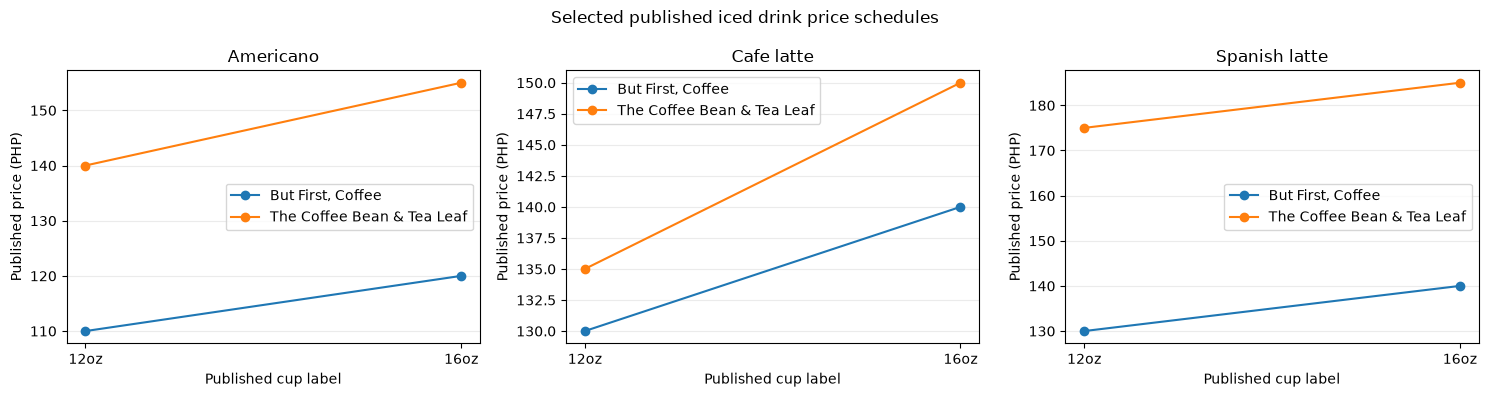

Matched schedules: 12
Cup labels are not measured beverage volumes.
No correlation, regression, or hypothesis test performed.
No files changed.


In [17]:
# Compare published 12oz and 16oz prices within each brand,
# product group, temperature, channel, and location scope.

import pandas as pd
import matplotlib.pyplot as plt

menu = datasets["menu_pricing"].copy()

selected_sources = ["SRC0030", "SRC0031", "SRC0032", "SRC0121"]

size_schedule = menu.loc[
    menu["source_id"].isin(selected_sources)
    & menu["temperature"].isin(["Hot", "Iced"])
    & menu["size_label_standardised"].isin(["12oz", "16oz"])
    & menu["displayed_price_php"].notna(),
    [
        "observation_id",
        "brand_id",
        "source_id",
        "comparison_group",
        "temperature",
        "channel",
        "location_scope",
        "size_label_standardised",
        "displayed_price_php",
    ],
].copy()

match_fields = [
    "brand_id",
    "comparison_group",
    "temperature",
    "channel",
    "location_scope",
]

# Stop if the selected evidence contains competing records
# for the same size within a comparison group.
duplicate_sizes = size_schedule.duplicated(
    subset=match_fields + ["size_label_standardised"],
    keep=False,
)

if duplicate_sizes.any():
    display(size_schedule.loc[duplicate_sizes])
    raise ValueError(
        "Multiple records found for a size. Review them before pairing."
    )

small = size_schedule.loc[
    size_schedule["size_label_standardised"].eq("12oz")
].drop(columns="size_label_standardised")

large = size_schedule.loc[
    size_schedule["size_label_standardised"].eq("16oz")
].drop(columns="size_label_standardised")

size_price_pairs = small.merge(
    large,
    on=match_fields,
    how="inner",
    suffixes=("_12oz", "_16oz"),
    validate="one_to_one",
)

size_price_pairs = size_price_pairs.merge(
    datasets["competitor_master"][["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)

size_price_pairs["price_increment_php"] = (
    size_price_pairs["displayed_price_php_16oz"]
    - size_price_pairs["displayed_price_php_12oz"]
)

size_price_pairs = size_price_pairs.sort_values(
    ["comparison_group", "temperature", "brand_name"]
).reset_index(drop=True)

print("Published size and price schedules:")
display(
    size_price_pairs[
        [
            "brand_name",
            "comparison_group",
            "temperature",
            "displayed_price_php_12oz",
            "displayed_price_php_16oz",
            "price_increment_php",
            "source_id_12oz",
            "source_id_16oz",
        ]
    ]
)

# Plot iced schedules only because the hot prices repeat
# the same recorded pattern in these selected menus.
iced_schedules = size_price_pairs.loc[
    size_price_pairs["temperature"].eq("Iced")
]

products = sorted(iced_schedules["comparison_group"].unique())

if products:
    fig, axes = plt.subplots(
        1,
        len(products),
        figsize=(5 * len(products), 4),
        squeeze=False,
    )

    for ax, product in zip(axes.flat, products):
        product_rows = iced_schedules.loc[
            iced_schedules["comparison_group"].eq(product)
        ]

        for _, row in product_rows.iterrows():
            ax.plot(
                [12, 16],
                [
                    float(row["displayed_price_php_12oz"]),
                    float(row["displayed_price_php_16oz"]),
                ],
                marker="o",
                label=row["brand_name"],
            )

        ax.set_title(product)
        ax.set_xticks([12, 16], ["12oz", "16oz"])
        ax.set_xlabel("Published cup label")
        ax.set_ylabel("Published price (PHP)")
        ax.grid(axis="y", alpha=0.25)
        ax.legend()

    fig.suptitle("Selected published iced drink price schedules")
    fig.tight_layout()
    plt.show()

print("Matched schedules:", len(size_price_pairs))
print("Cup labels are not measured beverage volumes.")
print("No correlation, regression, or hypothesis test performed.")
print("No files changed.")

### Published size and price findings

Purpose

Compare the additional published price for moving from a 12oz cup label to a 16oz cup label within each selected drink.

Findings

| Product | BFC price increment | CBTL price increment |
| :--- | ---: | ---: |
| Americano | PHP 10 | PHP 15 |
| Cafe latte | PHP 10 | PHP 15 |
| Spanish latte | PHP 10 | PHP 10 |

The recorded hot and iced prices follow the same schedules.

BFC applies a PHP 10 increment across the three selected products. CBTL applies PHP 15 for Americano and Cafe latte, and PHP 10 for Spanish latte.

Business implication

BFC has a consistent size upgrade price across these selected products. Its recorded increment is PHP 5 lower for Americano and Cafe latte, and equal for Spanish latte.

Limitations

These findings describe selected published menus. Price freshness and branch applicability remain unresolved.

Cup labels do not establish measured beverage volume, espresso quantity, ingredient content, or customer value.

The 12 schedules repeat the same six brand and product patterns across hot and iced drinks. They are not 12 independent observations.

No correlation or hypothesis test is used because these selected price schedules do not provide an independent sample for population inference.

### Hypothesis readiness assessment

Purpose

Identify which research questions support descriptive analysis and which require additional evidence before statistical testing.

A numerical difference does not automatically justify a hypothesis test. The observations must represent suitable units, and the sampling method must support the intended conclusion.

Critical values and rejection region charts will be produced when a valid statistical test is available. Unsupported tests will remain deferred.

In [18]:
# Document the readiness of proposed statistical comparisons.

hypothesis_readiness = pd.DataFrame(
    [
        {
            "research_question_id": "RQ01",
            "proposed_relationship": "Equivalent drink prices differ by brand",
            "available_evidence": "12 candidate BFC and CBTL menu pairs",
            "current_analysis": "Published price differences",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Confirm product equivalence, current prices, branch scope "
                "and an appropriate sampling design. Hot and iced prices "
                "repeat the same six brand and product patterns."
            ),
        },
        {
            "research_question_id": "RQ02",
            "proposed_relationship": "Product category availability differs by brand",
            "available_evidence": "Selected menu listings across 21 brands",
            "current_analysis": "Recorded category coverage",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Collect menus using a consistent category checklist. "
                "Missing listings cannot be treated as product absence."
            ),
        },
        {
            "research_question_id": "RQ03",
            "proposed_relationship": "Comparable reward value differs by program",
            "available_evidence": "Three loyalty records and one promotion",
            "current_analysis": "Published mechanics comparison",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Confirm qualifying spend, reward values, validity, "
                "eligibility and comparable purchase scenarios."
            ),
        },
        {
            "research_question_id": "RQ04",
            "proposed_relationship": "Service time differs by store format",
            "available_evidence": "Three published store concept statements",
            "current_analysis": "Concept descriptions only",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Collect timed branch observations using consistent start "
                "and end events within comparable formats and conditions."
            ),
        },
        {
            "research_question_id": "RQ05",
            "proposed_relationship": "Customer sentiment differs by brand",
            "available_evidence": "36 platform selected comments from three brands",
            "current_analysis": "Draft topic and sentiment counts",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Review the draft coding and collect comparable documented "
                "samples. Current comment selection does not support "
                "population sentiment comparisons."
            ),
        },
        {
            "research_question_id": "RQ06",
            "proposed_relationship": "Ordering time differs by channel",
            "available_evidence": "Five published channel descriptions",
            "current_analysis": "Documented ordering features",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Observe comparable ordering journeys and record completion "
                "times, fees, branch identity and operating conditions."
            ),
        },
        {
            "research_question_id": "RQ07",
            "proposed_relationship": "Operating branch distribution differs by brand",
            "available_evidence": "24 listed or provisional directory entries",
            "current_analysis": "Directory coverage and identity issues",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Resolve aliases and verify operating status. Establish "
                "a complete directory or a suitable branch sampling design."
            ),
        },
        {
            "research_question_id": "RQ08",
            "proposed_relationship": "Comparable franchise investment differs by brand",
            "available_evidence": "15 records covering 11 brands",
            "current_analysis": "Published terms and package starting prices",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Obtain comparable formats, investment definitions, "
                "inclusions, exclusions, taxes and current quotations."
            ),
        },
        {
            "research_question_id": "RQ09",
            "proposed_relationship": "Equivalent event package prices differ by brand",
            "available_evidence": "12 BFC packages and selected competitor terms",
            "current_analysis": "BFC package price schedules",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Collect equivalent competitor packages with confirmed "
                "cup quantities, service scope, taxes and logistics."
            ),
        },
        {
            "research_question_id": "RQ10",
            "proposed_relationship": "Equivalent prices changed over time",
            "available_evidence": "Menu observations dated 2026-10-23",
            "current_analysis": "Baseline descriptions and recheck differences",
            "test_status": "Deferred",
            "remaining_requirement": (
                "Collect independently dated comparable observations "
                "from multiple periods. Same day retrieval differences "
                "do not establish a historical price change."
            ),
        },
    ]
)

display(hypothesis_readiness)

print("Research questions assessed:", len(hypothesis_readiness))
print("\nStatistical test readiness:")
display(
    hypothesis_readiness["test_status"]
    .value_counts()
    .rename_axis("test_status")
    .reset_index(name="research_questions")
)

print("No statistical tests performed.")
print("No files changed.")

,research_question_id,proposed_relationship,available_evidence,current_analysis,test_status,remaining_requirement
0,RQ01,Equivalent drink prices differ by brand,12 candidate BFC and CBTL menu pairs,Published price differences,Deferred,"Confirm product equivalence, current prices, b..."
1,RQ02,Product category availability differs by brand,Selected menu listings across 21 brands,Recorded category coverage,Deferred,Collect menus using a consistent category chec...
2,RQ03,Comparable reward value differs by program,Three loyalty records and one promotion,Published mechanics comparison,Deferred,"Confirm qualifying spend, reward values, valid..."
3,RQ04,Service time differs by store format,Three published store concept statements,Concept descriptions only,Deferred,Collect timed branch observations using consis...
4,RQ05,Customer sentiment differs by brand,36 platform selected comments from three brands,Draft topic and sentiment counts,Deferred,Review the draft coding and collect comparable...
5,RQ06,Ordering time differs by channel,Five published channel descriptions,Documented ordering features,Deferred,Observe comparable ordering journeys and recor...
6,RQ07,Operating branch distribution differs by brand,24 listed or provisional directory entries,Directory coverage and identity issues,Deferred,Resolve aliases and verify operating status. E...
7,RQ08,Comparable franchise investment differs by brand,15 records covering 11 brands,Published terms and package starting prices,Deferred,"Obtain comparable formats, investment definiti..."
8,RQ09,Equivalent event package prices differ by brand,12 BFC packages and selected competitor terms,BFC package price schedules,Deferred,Collect equivalent competitor packages with co...
9,RQ10,Equivalent prices changed over time,Menu observations dated 2026-10-23,Baseline descriptions and recheck differences,Deferred,Collect independently dated comparable observa...


Research questions assessed: 10

Statistical test readiness:


,test_status,research_questions
0,Deferred,10


No statistical tests performed.
No files changed.


### Statistical readiness findings

The available evidence supports descriptive comparisons of selected published prices, product listings, loyalty mechanics, franchise terms and commercial offers.

All 10 proposed statistical comparisons remain deferred. The main limitations are incomplete comparability, selective collection, missing measurements and unresolved historical dates.

The 36 customer comments support exploratory topic counts only. Their percentages describe the collected comments and cannot estimate the probability of feedback among all customers. Coding remains provisional until reviewed.

Within the 39 narrowly defined price groups screened, each group contains one observation. These groups cannot support meaningful distribution, normality or statistical outlier assessment.

No inferential correlation, significance test or rejection region chart is reported. Consequently, no decision to reject or fail to reject a null hypothesis is made.

The next collection cycle should address the requirements recorded for each research question. Existing descriptive findings remain qualified by their source coverage and comparability.

In [19]:
# Save EDA tables without changing the prepared or raw datasets.

from pathlib import Path
from datetime import datetime
import shutil
import pandas as pd

project_root = Path.cwd().resolve()

while (
    not (project_root / "data" / "processed").is_dir()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "data" / "processed").is_dir():
    raise FileNotFoundError("Run this notebook from inside the project folder.")

eda_path = project_root / "reports" / "eda"
eda_path.mkdir(parents=True, exist_ok=True)

# Variable names match the tables created earlier in Notebook 04.
table_names = [
    "brand_coverage",
    "coverage_summary",
    "price_pairs",
    "category_profile",
    "brand_category_coverage",
    "review_codebook",
    "review_codes",
    "coded_reviews",
    "topic_counts",
    "sentiment_counts",
    "screening_summary",
    "price_group_summary",
    "size_price_pairs",
    "hypothesis_readiness",
]

# Check everything before writing any files.
missing_tables = [
    name
    for name in table_names
    if name not in globals()
]

if missing_tables:
    raise ValueError(
        "Run the earlier EDA cells first. Missing tables: "
        + ", ".join(missing_tables)
    )

for name in table_names:
    if not isinstance(globals()[name], pd.DataFrame):
        raise TypeError(f"{name} must be a pandas DataFrame.")

draft_tables = [
    "review_codes",
    "coded_reviews",
    "topic_counts",
    "sentiment_counts",
]

export_tables = {}

for name in table_names:
    table = globals()[name].copy()

    if name in draft_tables:
        table["analysis_status"] = "Draft; analyst coding review pending"
        filename = f"draft_{name}.csv"
    else:
        filename = f"{name}.csv"

    export_tables[filename] = table

manifest_path = eda_path / "eda_export_manifest.csv"

existing_files = [
    eda_path / filename
    for filename in export_tables
    if (eda_path / filename).is_file()
]

if manifest_path.is_file():
    existing_files.append(manifest_path)

if existing_files:
    backup_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_path = eda_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    for file_path in existing_files:
        shutil.copy2(file_path, backup_path / file_path.name)

saved_tables = []

for filename, table in export_tables.items():
    table.to_csv(eda_path / filename, index=False)

    saved_tables.append(
        {
            "file": filename,
            "records_saved": len(table),
            "columns_saved": len(table.columns),
            "status": (
                "Draft; analyst coding review pending"
                if filename.startswith("draft_")
                else "Descriptive analysis or readiness assessment"
            ),
        }
    )

eda_export_manifest = pd.DataFrame(saved_tables)

eda_export_manifest.to_csv(manifest_path, index=False)

display(eda_export_manifest)

print("EDA tables saved:", len(eda_export_manifest))
print("Saved folder:", eda_path)
print("Raw and prepared datasets were not changed.")
print("Charts are not exported by this cell.")

,file,records_saved,columns_saved,status
0,brand_coverage.csv,23,13,Descriptive analysis or readiness assessment
1,coverage_summary.csv,10,5,Descriptive analysis or readiness assessment
2,price_pairs.csv,12,11,Descriptive analysis or readiness assessment
3,category_profile.csv,6,5,Descriptive analysis or readiness assessment
4,brand_category_coverage.csv,23,9,Descriptive analysis or readiness assessment
5,review_codebook.csv,8,2,Descriptive analysis or readiness assessment
6,draft_review_codes.csv,36,7,Draft; analyst coding review pending
7,draft_coded_reviews.csv,36,23,Draft; analyst coding review pending
8,draft_topic_counts.csv,8,5,Draft; analyst coding review pending
9,draft_sentiment_counts.csv,5,5,Draft; analyst coding review pending


EDA tables saved: 14
Saved folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/eda
Raw and prepared datasets were not changed.
Charts are not exported by this cell.


### EDA conclusion

The exploratory analysis supports qualified descriptions of the collected evidence across RQ01 to RQ10.

Selected BFC published prices are lower than the corresponding CBTL candidate prices. Product equivalence, freshness and branch applicability still require confirmation.

Customer feedback findings remain exploratory. The 36 platform selected comments do not represent all customers, and their proposed coding requires analyst review.

Evidence on store experience, ordering, branch networks, franchise offers and commercial packages remains incomplete.

All 10 proposed statistical comparisons remain deferred. No population estimates, significance conclusions or predictive performance claims are made.

Fourteen analysis tables and an export manifest are saved in reports/eda. Charts remain displayed in this notebook and have not been exported.

This completes the initial descriptive EDA pass. Further collection and coding review are required before expanding the conclusions.

### Analyst Review of Customer Comment Coding

Purpose

Check whether each proposed sentiment and topic label accurately
reflects the original comment.

Read the complete comment alongside its proposed labels and
coding explanation.

Use Mixed when the comment expresses both praise and criticism.
Keep unclear meaning unresolved.

Check comments comparing branches carefully. Do not attribute
every statement to the sampled branch.

The labels remain draft until the analyst completes the review.

In [20]:
# Display the first review batch without changing any labels.

review_batch = coded_reviews.sort_values("review_id").iloc[:12].copy()

review_columns = [
    "review_id",
    "brand_name",
    "review_text",
    "overall_sentiment",
    "topics",
    "coding_note",
    "coding_status",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(review_batch[review_columns])

print("Comments displayed:", len(review_batch))
print("Labels remain draft. No files changed.")

,review_id,brand_name,review_text,overall_sentiment,topics,coding_note,coding_status
0,REV0001,"But First, Coffee",Yummy coffee,Positive,Product quality,Praises coffee taste.,Draft; analyst review pending
1,REV0002,"But First, Coffee",Great drink + followed my special requests also,Positive,Product quality;Order accuracy,Praises drink and adherence to requests.,Draft; analyst review pending
2,REV0003,"But First, Coffee",Favorite Coffee from But First!! 💯,Positive,General feedback,Expresses preference without a specific quality attribute.,Draft; analyst review pending
3,REV0004,"But First, Coffee","super tapang ng coffee, i like it. kaso wala yung whipped cream na add ons ko haha",Mixed,Product quality;Order accuracy,Likes strong coffee but reports missing whipped cream.,Draft; analyst review pending
4,REV0005,"But First, Coffee","Ganun lang pala yung matcha strawberry nila. Nilagyan lang ng dried strawberry fruit. Tapos for me, lasang lasa mo na dahon yung matcha niya hindi tulad sa ibang branch na maayos. Nasad naman ako dito",Negative,Product quality;Consistency,Criticises matcha and compares it with another branch.,Draft; analyst review pending
5,REV0006,"But First, Coffee",Di standard serving nila. Kasi yung tres leches di naman shaken pero di puno. Sabi ng staff d daw tlga puno kasi shaken. DISAPPOINTED. Yung lasa walang special. NILAGYAN namin onting tubig para dumami,Negative,Product quality;Portion and ice;Consistency,"Criticises taste, fill level and serving standardisation.",Draft; analyst review pending
6,REV0007,"But First, Coffee",Not a single shot was in my drinks. So….it’s coffee shop who don’t put coffee in their drinks. Cool.,Negative,Product quality,Alleges missing espresso; this is not independently verified.,Draft; analyst review pending
7,REV0008,ZUS Coffee,"BEST! All ZUS Coffee around Taft really had the best quality. I went to Cebu and for some reasons, the Cebu branch couldn't get the same taste as how they prepare it in Taft Branches.",Mixed,Product quality;Consistency,Praises Taft and criticises Cebu. Mixed scope; not solely a Taft complaint.,Draft; analyst review pending
8,REV0009,ZUS Coffee,Super consistent on how the packed our drinks superb and the taste is definitely amazing. Sarap ulit ulitin di nakakasawa. 🥰❤️,Positive,Product quality;Packaging and accessories;Consistency,Praises taste and consistently good packing.,Draft; analyst review pending
9,REV0010,ZUS Coffee,"I recommend their strawberry line, super Sarap!!!",Positive,Product quality,Recommends strawberry drinks for taste.,Draft; analyst review pending


Comments displayed: 12
Labels remain draft. No files changed.


In [21]:
# Display comments 13 through 24 without changing labels.

review_batch = coded_reviews.sort_values("review_id").iloc[12:24].copy()

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(review_batch[review_columns])

print("Comments displayed:", len(review_batch))
print("Labels remain draft. No files changed.")

,review_id,brand_name,review_text,overall_sentiment,topics,coding_note,coding_status
12,REV0013,ZUS Coffee,You can taste the matcha also it was perfectly made.,Positive,Product quality,Praises matcha flavour and preparation.,Draft; analyst review pending
13,REV0014,ZUS Coffee,Barely any chocolate in the Pain Au,Negative,Product quality;Portion and ice,Reports little chocolate filling in the pastry.,Draft; analyst review pending
14,REV0015,ZUS Coffee,too sweets,Negative,Product quality,Criticises sweetness.,Draft; analyst review pending
15,REV0016,ZUS Coffee,Hindi puno ung cup. Ilang order na ako sa Zus. Eto ung pinaka-konti at disappointed. Almost half full lang.,Negative,Portion and ice;Consistency,Reports a lower fill level than previous orders.,Draft; analyst review pending
16,REV0017,ZUS Coffee,They serve iced coconut latte instead of extra hot coconut latte☹️,Negative,Order accuracy,Reports receiving iced instead of extra hot.,Draft; analyst review pending
17,REV0018,ZUS Coffee,I ordered 2 Iced SEASALT spanish latte and both did not have any. Akala ko honest mistake lang yung dati kong order pero naulit nanaman,Negative,Order accuracy;Consistency,Reports a repeated omission. The missing component is not explicitly named.,Draft; analyst review pending
18,REV0019,ZUS Coffee,too sweet and lots of ice. seems like the instructions were not followed.,Negative,Product quality;Portion and ice;Order accuracy,"Criticises sweetness, ice and apparent failure to follow instructions.",Draft; analyst review pending
19,REV0020,ZUS Coffee,I got wrong order I recieve both iced seasalt dark chocolate,Negative,Order accuracy,Reports receiving the wrong drinks.,Draft; analyst review pending
20,REV0021,ZUS Coffee,"I noted “Less sweetener po, less sweet” but this is the sweetest drink i’ve ever received from Zus",Negative,Product quality;Order accuracy,Criticises sweetness despite a less sweet instruction.,Draft; analyst review pending
21,REV0022,Starbucks,"Well packed, and complete",Positive,Packaging and accessories;Order accuracy,Praises packing and order completeness.,Draft; analyst review pending


Comments displayed: 12
Labels remain draft. No files changed.


In [22]:
# Display comments 25 through 36 without changing labels.

review_batch = coded_reviews.sort_values("review_id").iloc[24:36].copy()

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(review_batch[review_columns])

print("Comments displayed:", len(review_batch))
print("Labels remain draft. No files changed.")

,review_id,brand_name,review_text,overall_sentiment,topics,coding_note,coding_status
24,REV0025,Starbucks,Not the usual taste of my favorite drink. ☹ didnt finish it until now.,Negative,Product quality;Consistency,Reports an unusual taste compared with the usual drink.,Draft; analyst review pending
25,REV0026,Starbucks,damot sa yelo akala mo malugi sa yelo,Negative,Portion and ice,Criticises insufficient ice.,Draft; analyst review pending
26,REV0027,Starbucks,sobrang tapang ng kape,Unclear,Product quality,Strong coffee is described without an explicit preference.,Draft; analyst review pending
27,REV0028,Starbucks,WALANG STRAW,Negative,Packaging and accessories,Reports a missing straw.,Draft; analyst review pending
28,REV0029,Starbucks,Why nman ganito yung flatbread po huhu super tigas and sunog na wala pa naman pong 20minz yung del time. :(,Negative,Product quality,"Criticises hard and burnt flatbread. Delivery duration is context, not a stated delay.",Draft; analyst review pending
29,REV0030,Starbucks,wala ung add ons na dalawang coffee jelly at kulang nang madaming straw,Negative,Order accuracy;Packaging and accessories,Reports missing coffee jelly additions and insufficient straws.,Draft; analyst review pending
30,REV0031,Starbucks,I said add sugar on the instructions my god,Negative,Order accuracy,Expresses dissatisfaction about the sugar instruction.,Draft; analyst review pending
31,REV0032,Starbucks,"Inorder ko Tall, Grande yung dumating. 9 na tall tas isang grande . napagbaliktad yung size",Negative,Order accuracy,Reports incorrect size allocation.,Draft; analyst review pending
32,REV0033,Starbucks,order ko with whippe cream dumating wala,Negative,Order accuracy,Reports missing requested whipped cream.,Draft; analyst review pending
33,REV0034,Starbucks,Uyy bkt tall ang stroberry ko at wala pang strow nakka umay kayu,Negative,Order accuracy;Packaging and accessories,Questions received size and reports a missing straw. Expected size is unspecified.,Draft; analyst review pending


Comments displayed: 12
Labels remain draft. No files changed.


### Coding Review Findings

All 36 comments were displayed in three batches and examined
alongside their proposed sentiment, topics and coding notes.

No label changes were identified during this assisted review.

Ambiguous sentiment remains Unclear. Customer allegations,
cross branch comparisons and unspecified missing items retain
their qualifications.

This review is not independent double coding and does not
establish agreement between separate coders.

The coding remains provisional until the project analyst
confirms acceptance.

The results describe the collected platform selected comments.
They do not establish customer complaint prevalence or
comparative brand satisfaction.

In [23]:
# Save the assisted review outcome without changing coding approval.

coding_review_note = pd.DataFrame(
    [
        {
            "review_scope": "REV0001 through REV0036",
            "comments_examined": 36,
            "review_method": "Comments displayed and discussed in three batches",
            "label_changes_identified": 0,
            "analyst_approval": "Pending explicit confirmation",
            "coding_status": "Provisional",
            "independent_double_coding": "No",
            "limitation": (
                "Platform selected comments. Results do not represent "
                "all customers or comparative brand satisfaction."
            ),
        }
    ]
)

coding_review_note_path = (
    project_root / "reports" / "eda" / "coding_review_note.csv"
)

coding_review_note_path.parent.mkdir(parents=True, exist_ok=True)

if coding_review_note_path.exists():
    print("Review note already exists. No file replaced.")
else:
    coding_review_note.to_csv(coding_review_note_path, index=False)
    print("Saved:", coding_review_note_path)

display(coding_review_note)

print("Comment labels and coding approval status were not changed.")

Review note already exists. No file replaced.


,review_scope,comments_examined,review_method,label_changes_identified,analyst_approval,coding_status,independent_double_coding,limitation
0,REV0001 through REV0036,36,Comments displayed and discussed in three batches,0,Pending explicit confirmation,Provisional,No,Platform selected comments. Results do not rep...


Comment labels and coding approval status were not changed.


## Evidence Periods for the Refreshed Analysis

The study baseline remains October 23, 2026.

Observations captured after that date are analyzed separately
as supplementary evidence.

The two V Mapa food observations were extracted on October 25
from a preserved October 23 capture. They belong to the capture
baseline but were absent from the original 129 record analysis.

Collection dates do not establish price effective dates.

Baseline and supplementary records must not be pooled to
claim historical changes or independent confirmations.

In [24]:
# Separate menu observations by capture period.
# Loaded datasets and saved files remain unchanged.

baseline_date = pd.Timestamp("2026-10-23")

menu_analysis = all_datasets["menu_pricing"].copy()

menu_analysis["observed_date"] = pd.to_datetime(
    menu_analysis["observed_date"],
    errors="raise",
)

menu_analysis["evidence_period"] = "Date missing"

menu_analysis.loc[
    menu_analysis["observed_date"].le(baseline_date),
    "evidence_period",
] = "Captured on or before baseline"

menu_analysis.loc[
    menu_analysis["observed_date"].gt(baseline_date),
    "evidence_period",
] = "Captured after baseline"

# Retrospective extraction is a separate qualification.

menu_analysis["retrospective_food_extraction"] = (
    menu_analysis["observation_id"].isin(["MNU0245", "MNU0246"])
)

baseline_menu = menu_analysis.loc[
    menu_analysis["evidence_period"].eq(
        "Captured on or before baseline"
    )
].copy()

supplementary_menu = menu_analysis.loc[
    menu_analysis["evidence_period"].eq(
        "Captured after baseline"
    )
].copy()

menu_period_summary = (
    menu_analysis.groupby("evidence_period", dropna=False)
    .agg(
        records=("observation_id", "size"),
        sources=("source_id", "nunique"),
        brands=("brand_id", "nunique"),
        retrospective_food_records=(
            "retrospective_food_extraction", "sum"
        ),
    )
    .reset_index()
)

print("Menu evidence periods:")
display(menu_period_summary)

print("\nObservation dates:")
display(
    menu_analysis.groupby("observed_date", dropna=False)
    .size()
    .reset_index(name="records")
)

print("Total menu observations:", len(menu_analysis))
print("Capture baseline records:", len(baseline_menu))
print("Supplementary records:", len(supplementary_menu))
print("Retrospectively extracted food records: 2")
print("No price changes inferred. No files changed.")

Menu evidence periods:


,evidence_period,records,sources,brands,retrospective_food_records
0,Captured after baseline,115,3,2,0
1,Captured on or before baseline,131,33,21,2



Observation dates:


,observed_date,records
0,2026-10-23,131
1,2026-10-25,115


Total menu observations: 246
Capture baseline records: 131
Supplementary records: 115
Retrospectively extracted food records: 2
No price changes inferred. No files changed.


### RQ10 Findings

The prepared menu dataset contains 246 observations.

Of these, 131 observations from 33 sources across 21 brands were
captured on October 23, 2026. This includes two food observations
extracted later from a preserved baseline capture.

The remaining 115 observations from three sources across two brands
were captured on October 25, 2026.

The original baseline analysis contained 129 observations. The additional
records reflect expanded collection and retrospective extraction.
They do not establish changes in prices or product availability.

Price differences between retrieved versions remain qualified by
serving details, channel, location and promotion conditions.

## Supplementary Product Catalogs

Catalogs preserve product descriptions and published categories.

They use different observation structures from menu pricing.
Their row counts must not be added to menu observation counts.

Where a catalog row links to an existing menu observation,
it enriches that observation rather than adding another price.

Unpriced directory listings remain separate evidence.

In [25]:
# 1. Load the prepared catalogs and restore their saved field types.

catalogs_path = project_root / "data" / "processed" / "catalogs"

catalog_manifest = pd.read_csv(
    catalogs_path / "catalog_manifest.csv",
    dtype="string",
)

catalog_field_types = pd.read_csv(
    catalogs_path / "catalog_field_types.csv",
    dtype="string",
)

catalogs = {}

for _, entry in catalog_manifest.iterrows():
    catalog_name = entry["catalog"]

    df = pd.read_csv(
        catalogs_path / entry["filename"],
        dtype="string",
    )

    definitions = catalog_field_types.loc[
        catalog_field_types["catalog"].eq(catalog_name)
    ]

    if set(df.columns) != set(definitions["field"]):
        raise ValueError(f"Field definitions differ: {catalog_name}")

    for _, definition in definitions.iterrows():
        field = definition["field"]
        data_type = definition["pandas_dtype"]

        if data_type.startswith("datetime64"):
            df[field] = pd.to_datetime(
                df[field],
                format="%Y-%m-%d",
                errors="raise",
            )
        else:
            df[field] = df[field].astype(data_type)

    catalogs[catalog_name] = df

# 2. Check exact links without matching names across different sources.

menu = all_datasets["menu_pricing"]

menu_keys = menu[
    ["brand_id", "product_name", "source_id"]
].drop_duplicates()

overlap_rows = []

for catalog_name, df in catalogs.items():
    if "observation_id" in df.columns:
        linked_menu = df.merge(
            menu[
                [
                    "observation_id",
                    "brand_id",
                    "product_name",
                    "source_id",
                    "displayed_price_php",
                ]
            ],
            on="observation_id",
            how="left",
            suffixes=("_catalog", "_menu"),
            validate="one_to_one",
            indicator=True,
        )

        if not linked_menu["_merge"].eq("both").all():
            raise ValueError(f"Unknown menu observations: {catalog_name}")

        for field in [
            "brand_id",
            "product_name",
            "source_id",
            "displayed_price_php",
        ]:
            if linked_menu[f"{field}_catalog"].ne(
                linked_menu[f"{field}_menu"]
            ).fillna(True).any():
                raise ValueError(
                    f"Catalog and menu disagree: {catalog_name}, {field}"
                )

        linked_count = len(linked_menu)

    else:
        linked_menu = df.merge(
            menu_keys,
            on=["brand_id", "product_name", "source_id"],
            how="left",
            validate="many_to_one",
            indicator=True,
        )

        linked_count = int(linked_menu["_merge"].eq("both").sum())

    overlap_rows.append(
        {
            "catalog": catalog_name,
            "catalog_records": len(df),
            "exact_links_to_menu": linked_count,
            "without_exact_menu_link": len(df) - linked_count,
        }
    )

catalog_menu_overlap = pd.DataFrame(overlap_rows)

display(catalog_menu_overlap)

print("Catalog rows:", catalog_menu_overlap["catalog_records"].sum())
print(
    "Exact menu links:",
    catalog_menu_overlap["exact_links_to_menu"].sum(),
)
print("No cross source product equivalence inferred.")
print("Catalog rows were not appended to menu pricing.")
print("No files changed.")

,catalog,catalog_records,exact_links_to_menu,without_exact_menu_link
0,pickup_product_profile,74,74,0
1,zus_product_catalog,36,0,36
2,zus_food_catalog,19,0,19
3,bigbrew_product_catalog,12,0,12


Catalog rows: 141
Exact menu links: 74
No cross source product equivalence inferred.
Catalog rows were not appended to menu pricing.
No files changed.


## Direct Competitor Pricing Diagnostic

Research alignment: RQ01.

The choice of benchmark affects the commercial interpretation.

Earlier candidate comparisons placed BFC below CBTL.
The supplementary captures show higher BFC displayed prices
for selected corresponding PICKUP listings.

Neither comparison supports a blanket claim that BFC is
cheaper or more expensive than competitors.

For this diagnostic, use BFC's explicit 12oz iced Americano.
Other BFC listings and PICKUP listings retain unresolved
serving details.

Displayed differences identify questions for investigation.
They do not establish equivalent product savings or value.

In [26]:
# Use supplementary captures only for this diagnostic.

menu = supplementary_menu.copy()

diagnostic_products = pd.DataFrame(
    [
        ["Americano", "Americano", "AMERICANO"],
        ["Cafe latte", "Cafe Latte", "ICED LATTE"],
        ["Spanish style latte", "Spanish Latte", "KAPE KASTILA"],
        [
            "Caramel macchiato",
            "Caramel Macchiato",
            "ICED CARAMEL MACCHIATO",
        ],
        ["Matcha milk drink", "Matcha Latte", "ICED MATCHA"],
        ["Strawberry matcha", "Matcha Strawberry", "STRAWBERRY MATCHA"],
    ],
    columns=[
        "diagnostic_product_group",
        "bfc_product_name",
        "pickup_product_name",
    ],
)

selected_fields = [
    "observation_id",
    "source_id",
    "observed_date",
    "product_name",
    "temperature",
    "size_label_standardised",
    "displayed_price_php",
    "location_scope",
    "channel",
]

# Exclude the general Americano listing.
# Keep only the inspected 12oz iced option for that product.

bfc_selection = (
    (
        menu["source_id"].eq("SRC0126")
        & menu["product_name"].ne("Americano")
    )
    | (
        menu["source_id"].eq("SRC0127")
        & menu["temperature"].eq("Iced")
        & menu["size_label_standardised"].eq("12oz")
    )
).fillna(False)

bfc_listings = menu.loc[
    bfc_selection,
    selected_fields,
].add_prefix("bfc_")

pickup_listings = menu.loc[
    menu["source_id"].eq("SRC0125"),
    selected_fields,
].add_prefix("pickup_")

direct_price_diagnostic = diagnostic_products.merge(
    bfc_listings,
    on="bfc_product_name",
    how="left",
    validate="many_to_one",
).merge(
    pickup_listings,
    on="pickup_product_name",
    how="left",
    validate="many_to_one",
)

if direct_price_diagnostic[
    ["bfc_observation_id", "pickup_observation_id"]
].isna().any().any():
    raise ValueError("A specified product observation was not found.")

direct_price_diagnostic["bfc_minus_pickup_php"] = (
    direct_price_diagnostic["bfc_displayed_price_php"]
    - direct_price_diagnostic["pickup_displayed_price_php"]
)

direct_price_diagnostic["comparison_status"] = (
    "Displayed price diagnostic; serving equivalence unresolved"
)

display(
    direct_price_diagnostic[
        [
            "diagnostic_product_group",
            "bfc_displayed_price_php",
            "pickup_displayed_price_php",
            "bfc_minus_pickup_php",
            "bfc_temperature",
            "bfc_size_label_standardised",
            "pickup_temperature",
            "pickup_size_label_standardised",
        ]
    ]
)

print("Diagnostic pairs:", len(direct_price_diagnostic))
print("Americano uses SRC0127's explicit BFC 12oz iced option.")
print("Other serving details remain as recorded.")
print("Source identifiers and location contexts retained.")
print("No price changes, savings or equivalent value inferred.")
print("No files changed.")

,diagnostic_product_group,bfc_displayed_price_php,pickup_displayed_price_php,bfc_minus_pickup_php,bfc_temperature,bfc_size_label_standardised,pickup_temperature,pickup_size_label_standardised
0,Americano,110.0,50.0,60.0,Iced,12oz,Not stated,<NA>
1,Cafe latte,130.0,75.0,55.0,Not stated,<NA>,Iced,<NA>
2,Spanish style latte,130.0,75.0,55.0,Not stated,<NA>,Not stated,<NA>
3,Caramel macchiato,130.0,89.0,41.0,Not stated,<NA>,Iced,<NA>
4,Matcha milk drink,130.0,85.0,45.0,Not stated,<NA>,Iced,<NA>
5,Strawberry matcha,130.0,95.0,35.0,Not stated,<NA>,Not stated,<NA>


Diagnostic pairs: 6
Americano uses SRC0127's explicit BFC 12oz iced option.
Other serving details remain as recorded.
Source identifiers and location contexts retained.
No price changes, savings or equivalent value inferred.
No files changed.


## Product Proposition Comparison

Research alignment: RQ02, with implications for RQ01 and RQ09.

Compare documented offerings by purchase occasion and product
attribute rather than raw listing counts.

Distinguish a named product from a described recipe.
Distinguish an advertised category from inspected products.

Not established means the inspected evidence is insufficient.
It does not mean the brand lacks the offering.

The comparison combines identified captures from October 23
and October 25. It is not a synchronized branch menu audit.

In [27]:
# Summarize the inspected evidence without assigning competitive scores.

offering_comparison = pd.DataFrame(
    [
        {
            "comparison_area": "Entry coffee",
            "BFC": "Brewed PHP 65; preparation differs from Americano",
            "PICKUP": "Americano PHP 50; size unresolved",
            "ZUS": "Americano listed; official directory price unavailable",
            "BigBrew": "Coffee category advertised; product details unresolved",
            "evidence_references": "SRC0125;SRC0126;SRC0135;SRC0137",
            "decision_for_bfc": (
                "Clarify the eligible entry product and compare "
                "like preparation and serving before price claims."
            ),
        },
        {
            "comparison_area": "Coffee combined with matcha",
            "BFC": "Dirty Matcha named; recipe not captured",
            "PICKUP": "Combination not established in inspected descriptions",
            "ZUS": "Zirty Matcha explicitly describes coffee and matcha",
            "BigBrew": "Combination not established",
            "evidence_references": "SRC0125;SRC0126;SRC0128;SRC0135",
            "decision_for_bfc": (
                "Verify and communicate BFC's existing recipe before "
                "treating the competitor offering as a product gap."
            ),
        },
        {
            "comparison_area": "Refreshing coffee combinations",
            "BFC": "Comparable recipe not established",
            "PICKUP": "Comparable recipe not established",
            "ZUS": "Thunder describes espresso, honey lemon and tonic",
            "BigBrew": "Comparable recipe not established",
            "evidence_references": "SRC0125;SRC0126;SRC0129;SRC0135",
            "decision_for_bfc": (
                "Investigate local interest and operating feasibility "
                "before proposing a limited product test."
            ),
        },
        {
            "comparison_area": "Oat milk offerings",
            "BFC": "Not established in inspected menu",
            "PICKUP": "Five named listings in published OATMILK section",
            "ZUS": "Not established in inspected directory",
            "BigBrew": "Not established",
            "evidence_references": "SRC0125;SRC0126;SRC0135;SRC0137;SRC0138;SRC0139",
            "decision_for_bfc": (
                "Check existing substitutions and branch capability "
                "before identifying an assortment gap."
            ),
        },
        {
            "comparison_area": "Protein offerings",
            "BFC": "Not established in inspected menu",
            "PICKUP": "Four listings in PROTEIN UP section",
            "ZUS": "Not established in inspected directory",
            "BigBrew": "Not established",
            "evidence_references": "SRC0125;SRC0126;SRC0135;SRC0137;SRC0138;SRC0139",
            "decision_for_bfc": (
                "Assess customer demand, ingredient cost and verified "
                "product specifications before considering development."
            ),
        },
        {
            "comparison_area": "Food and eating occasions",
            "BFC": "Taisan and cheesecake listed at V Mapa",
            "PICKUP": "Five priced pastry and cookie listings",
            "ZUS": "Nineteen directory listings, including hot meals",
            "BigBrew": "Food offer not established",
            "evidence_references": "SRC0125;SRC0131;SRC0132;SRC0133;SRC0134;SRC0135;SRC0136",
            "decision_for_bfc": (
                "Establish current branch food coverage, then evaluate "
                "visibility, attachment, contribution and waste."
            ),
        },
    ]
)

with pd.option_context("display.max_colwidth", None):
    display(offering_comparison)

print("Comparison areas:", len(offering_comparison))
print("Evidence references retained for each comparison area.")
print("No absence claims, demand estimates or competitive scores assigned.")
print("No files changed.")

,comparison_area,BFC,PICKUP,ZUS,BigBrew,evidence_references,decision_for_bfc
0,Entry coffee,Brewed PHP 65; preparation differs from Americano,Americano PHP 50; size unresolved,Americano listed; official directory price unavailable,Coffee category advertised; product details unresolved,SRC0125;SRC0126;SRC0135;SRC0137,Clarify the eligible entry product and compare like preparation and serving before price claims.
1,Coffee combined with matcha,Dirty Matcha named; recipe not captured,Combination not established in inspected descriptions,Zirty Matcha explicitly describes coffee and matcha,Combination not established,SRC0125;SRC0126;SRC0128;SRC0135,Verify and communicate BFC's existing recipe before treating the competitor offering as a product gap.
2,Refreshing coffee combinations,Comparable recipe not established,Comparable recipe not established,"Thunder describes espresso, honey lemon and tonic",Comparable recipe not established,SRC0125;SRC0126;SRC0129;SRC0135,Investigate local interest and operating feasibility before proposing a limited product test.
3,Oat milk offerings,Not established in inspected menu,Five named listings in published OATMILK section,Not established in inspected directory,Not established,SRC0125;SRC0126;SRC0135;SRC0137;SRC0138;SRC0139,Check existing substitutions and branch capability before identifying an assortment gap.
4,Protein offerings,Not established in inspected menu,Four listings in PROTEIN UP section,Not established in inspected directory,Not established,SRC0125;SRC0126;SRC0135;SRC0137;SRC0138;SRC0139,"Assess customer demand, ingredient cost and verified product specifications before considering development."
5,Food and eating occasions,Taisan and cheesecake listed at V Mapa,Five priced pastry and cookie listings,"Nineteen directory listings, including hot meals",Food offer not established,SRC0125;SRC0131;SRC0132;SRC0133;SRC0134;SRC0135;SRC0136,"Establish current branch food coverage, then evaluate visibility, attachment, contribution and waste."


Comparison areas: 6
Evidence references retained for each comparison area.
No absence claims, demand estimates or competitive scores assigned.
No files changed.


In [28]:
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

# Preserve the supplementary analysis separately.

supplementary_path = project_root / "reports" / "supplementary"
supplementary_path.mkdir(parents=True, exist_ok=True)

supplementary_tables = {
    "menu_period_summary": menu_period_summary,
    "catalog_menu_overlap": catalog_menu_overlap,
    "direct_price_diagnostic": direct_price_diagnostic,
    "offering_comparison": offering_comparison,
}

# Check that the comparison references registered sources.

valid_source_ids = set(datasets["source_register"]["source_id"])

referenced_sources = (
    offering_comparison["evidence_references"]
    .str.split(";")
    .explode()
    .str.strip()
)

unknown_sources = set(referenced_sources) - valid_source_ids

if unknown_sources:
    raise ValueError(f"Unknown source references: {unknown_sources}")

# Back up earlier supplementary exports before replacement.

existing_files = [
    supplementary_path / f"{name}.csv"
    for name in supplementary_tables
    if (supplementary_path / f"{name}.csv").is_file()
]

if existing_files:
    backup_label = datetime.now(
        ZoneInfo("Asia/Manila")
    ).strftime("%Y%m%d_%H%M%S_%f")

    backup_path = supplementary_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    for file_path in existing_files:
        shutil.copy2(file_path, backup_path / file_path.name)

saved_rows = []

for name, table in supplementary_tables.items():
    table.to_csv(
        supplementary_path / f"{name}.csv",
        index=False,
        date_format="%Y-%m-%d",
    )

    saved_rows.append(
        {
            "file": f"{name}.csv",
            "records_saved": len(table),
            "columns_saved": len(table.columns),
        }
    )

display(pd.DataFrame(saved_rows))

print("Saved folder:", supplementary_path)
print("Original EDA exports were not replaced.")
print("Raw and prepared datasets were not changed.")

,file,records_saved,columns_saved
0,menu_period_summary.csv,2,5
1,catalog_menu_overlap.csv,4,4
2,direct_price_diagnostic.csv,6,21
3,offering_comparison.csv,6,7


Saved folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/supplementary
Original EDA exports were not replaced.
Raw and prepared datasets were not changed.


In [29]:
print("Complete menu records:", len(all_datasets["menu_pricing"]))
print("Baseline menu records:", len(datasets["menu_pricing"]))

Complete menu records: 246
Baseline menu records: 131


In [30]:
display(category_profile)
display(brand_category_coverage)

,product_category,listing_records,brands_recorded,sources_recorded,distinct_recorded_names
0,Coffee,103,13,22,36
3,Milk tea,13,5,7,10
1,Fries,4,1,1,4
2,Fruit shakes,3,1,1,3
4,Pastries,2,1,1,2
5,Waffles,3,1,1,3


,brand_id,brand_name,inclusion_status,Coffee,Fries,Fruit shakes,Milk tea,Pastries,Waffles
0,BFC001,"But First, Coffee",Reference,26,0,0,0,2,0
1,BFC002,PICKUP COFFEE,Included,6,0,0,0,0,0
2,BFC003,Juan Café,Included,3,0,0,0,0,0
3,BFC004,TOMO Coffee,Candidate,0,0,0,0,0,0
4,BFC005,TOMORO COFFEE,Candidate,6,0,0,0,0,0
5,BFC006,Macao Imperial Tea,Included,0,0,0,3,0,0
6,BFC007,Black Scoop Cafe,Included,3,0,0,0,0,0
7,BFC008,Kurimi Milk Tea Bar,Included,0,0,0,2,0,0
8,BFC009,Dunkin',Included,6,0,0,0,0,0
9,BFC010,Figaro Coffee,Included,4,0,0,0,0,0


### RQ02 Findings

The baseline category analysis retains 128 listing records across six
categories: coffee, milk tea, fries, fruit shakes, pastries and waffles.

Coffee accounts for 103 records across 13 brands. Milk tea accounts
for 13 records across five brands. Each remaining category has recorded
evidence from one brand.

The two pastry observations describe BFC Blueberry Cheesecake and
Taisan at V Mapa. They were extracted from a preserved October 23
capture and do not establish pastry availability at other branches.

### Business implication

The evidence supports reviewing beverage and food occasions separately.
Listing counts describe collection coverage, not assortment completeness,
product popularity or market share.

### Limitations

Zero records do not establish that a brand lacks a category.
The 128 retained records are a screened subset of the 131 baseline
menu observations. Supplementary catalogs are assessed separately.

In [31]:
print("Baseline promotions:", len(datasets["promotions"]))
print("Baseline loyalty records:", len(datasets["loyalty_programs"]))

print(
    "Complete promotions:",
    len(all_datasets["promotions"])
)

print(
    "Complete loyalty records:",
    len(all_datasets["loyalty_programs"])
)

Baseline promotions: 1
Baseline loyalty records: 3
Complete promotions: 3
Complete loyalty records: 4


In [32]:
print(
    "Baseline ordering records:",
    len(datasets["ordering_channels"])
)

print(
    "Complete ordering records:",
    len(all_datasets["ordering_channels"])
)

Baseline ordering records: 5
Complete ordering records: 6


## Local Study Across Four Areas

Research alignment: RQ01, RQ02, RQ06 and RQ07.

The selected locations are Diliman, Molino III, Jones and T. Chavez.
They represent four case studies, not a representative national sample.

Local diagnostics remain separate from prepared menu observations.
Starting prices, inspected size options and promotional prices retain
their evidence qualifications.

## Local Study Across Four Areas

Research alignment: RQ01, RQ02, RQ06 and RQ07.

The selected locations are Diliman, Molino III, Jones and T. Chavez.
They represent four case studies, not a representative national sample.

Local diagnostics remain separate from prepared menu observations.
Starting prices, inspected size options and promotional prices retain
their evidence qualifications.

In [34]:
local_site_evidence_summary = pd.read_csv(
    project_root
    / "reports/supplementary/local_site_evidence_summary.csv"
)

local_competitor_reconciled = pd.read_csv(
    project_root
    / "data/interim/local_competitor_reconciled.csv",
    dtype="string"
)

display(local_site_evidence_summary)

print(
    "Local competitor records:",
    len(local_competitor_reconciled)
)

print(
    "Registered option evidence links:",
    local_competitor_reconciled["option_source_id"].notna().sum()
)

,site_id,study_area,branch_name,city,shortlisted_competitors,recorded_starting_prices,accepted_size_panels
0,LOC0001,Metro Manila,Diliman,Quezon City,6,3,1
1,LOC0002,Luzon outside Metro Manila,Molino III,Bacoor,5,2,0
2,LOC0003,Visayas,Jones,Cebu City,8,5,1
3,LOC0004,Mindanao,T. Chavez,Cagayan de Oro,4,2,0


Local competitor records: 23
Registered option evidence links: 1


In [35]:
local_commercial_actions = pd.read_csv(
    project_root
    / "reports/supplementary/local_commercial_actions.csv",
    dtype="string"
)

with pd.option_context("display.max_colwidth", None):
    display(
        local_commercial_actions[
            [
                "branch_name",
                "evidence_basis",
                "proposed_action",
                "validation_required",
                "success_measure"
            ]
        ]
    )

,branch_name,evidence_basis,proposed_action,validation_required,success_measure
0,Diliman,BFC Americano starts at PHP 116; inspected PICKUP Regular is PHP 50. Serving equivalence unresolved.,Review entry coffee positioning against PICKUP Kalayaan.,Confirm comparable serving sizes and current branch prices.,A documented comparison with matched product and serving details.
1,Molino III,Recorded brewed coffee and banana bread total PHP 150. Costs and demand unresolved.,Assess a coffee and food offer using the existing assortment.,"Confirm item sales, costs, availability and waste.",A costed offer proposal supported by branch sales evidence.
2,Jones,Recorded brewed coffee and Revel Bar total PHP 136 using captured promotional prices.,Review promotion exposure and a coffee with Revel Bar offer.,"Confirm promotion funding, serving sizes and item contribution.",A costed offer proposal with documented promotion terms.
3,T. Chavez,Brewed coffee starts at PHP 85. Food availability and competitor serving prices unresolved.,Verify food availability and competitor serving options.,Confirm the branch food menu and local competitor prices.,A reviewed food menu and documented competitor serving prices.


### Local commercial interpretation

Diliman warrants investigation of entry coffee positioning against
PICKUP Kalayaan. Serving equivalence remains unresolved.

Molino III warrants assessment of a coffee and food offer using its
recorded assortment, supported by item sales, costs and waste.

Jones warrants review of promotion exposure and a possible coffee
with Revel Bar offer. The calculated combination is not an advertised
bundle.

T. Chavez requires confirmation of food availability and competitor
serving prices before developing a comparable offer.

These are proposed investigations. No assignments, approved offers,
sales uplift or profitability estimates are established.

In [36]:
digital_evidence_assessment = pd.read_csv(
    project_root
    / "reports/supplementary/digital_evidence_assessment.csv",
    dtype="string"
)

five_forces_assessment = pd.read_csv(
    project_root
    / "reports/supplementary/five_forces_assessment.csv",
    dtype="string"
)

display(digital_evidence_assessment)
display(five_forces_assessment)

,brand_id,brand_name,ordering_evidence,loyalty_evidence,key_validation_needed,evidence_references,qualification
0,BFC001,"But First, Coffee",Official ordering link and branded app promoti...,"Points, reward tiers and member benefits descr...",Reconcile app messaging; verify earning rules ...,SRC0062;SRC0122;SRC0123;SRC0126,Published evidence; active use and retention e...
1,BFC002,PICKUP COFFEE,"Order ahead, pickup and delivery described",Purchase points and tier benefits described,"Verify earning rate, qualifying spend, expiry ...",SRC0064;SRC0065;SRC0086,Published evidence; active use and retention e...
2,BFC021,ZUS Coffee,App ordering described; fulfilment modes unres...,App purchase points and rewards described,"Verify earning rate, tier thresholds, expiry a...",SRC0059,Published evidence; active use and retention e...
3,BFC022,Starbucks Philippines,No ordering record in the current channel table,One Star per PHP 25 qualifying card spend reco...,Verify ordering capabilities and applicable re...,SRC0066,Published evidence; active use and retention e...


,force,current_evidence,supported_interpretation,additional_evidence_required,evidence_reference,force_rating
0,Competitive rivalry,23 selected local competitors; 12 recorded Ame...,BFC faces several observed alternatives in the...,"Matched servings, local sales, customer prefer...",local_competitor_reconciled.csv;offering_compa...,Unrated
1,Threat of new entrants,15 franchise offer records across 11 brands; f...,Published franchise routes exist; actual entry...,"Total opening costs, permits, site access, ope...",franchise_offers.csv,Unrated
2,Threat of substitutes,Alternative beverage categories recorded; inst...,Category overlap is observed; substitution out...,Define the market boundary; collect alternativ...,pickup_product_profile.csv;zus_product_catalog...,Unrated
3,Buyer bargaining power,Multiple local alternatives and captured BFC p...,Customers have observed alternatives; switchin...,"Switching behaviour, price sensitivity and con...",local_competitor_reconciled.csv;local_price_ve...,Unrated
4,Supplier bargaining power,"No supplier concentration, purchasing contract...",Supplier power cannot be assessed from the cur...,"Supplier shares, alternative sources, contract...",Evidence gap,Unrated


## Digital Capabilities and Competitive Forces

The digital assessment compares recorded ordering and loyalty
propositions. It does not rank app performance or customer retention.

The Five Forces framework separates observed evidence from unanswered
questions. All five forces remain unrated because the current evidence
does not support defensible intensity scores.

Published capabilities do not establish operational availability.
Alternative offerings do not establish customer switching behaviour.

## Integrated Findings and Next Stage

### Supported findings

The prepared menu contains 131 baseline observations and 115
supplementary observations. These periods remain separate.

Selected BFC prices are below the candidate CBTL prices and above
selected PICKUP listings. Serving equivalence remains qualified,
so neither comparison establishes a general value ranking.

The four local case studies contain 23 shortlisted competitors,
12 recorded starting prices and two accepted product panels.
Only one panel currently has a registered source reference.

Captured promotions explain the displayed reductions at Diliman
and Jones. They do not establish promotion effectiveness.

BFC has recorded food and beverage offerings worth assessing before
assuming assortment gaps. Branch availability still requires checking.

### Commercial priorities

Validate comparable local servings and prices.

Assess existing coffee and food combinations using sales, costs,
availability and waste.

Reconcile BFC app messaging and document participating branches
and loyalty rules.

Collect evidence needed to assess entry barriers, substitution,
buyer power and supplier power.

### Statistical and modelling limitations

The current evidence does not support population estimates,
causal effects, price elasticity or validated sales predictions.

Statistical tests remain deferred where sampling, independence,
comparability or outcome data are insufficient. No rejection region
or hypothesis decision is reported without a valid test.

### Next stage

Review existing engineered features against the refreshed evidence.
Retain source identifiers, evidence periods and comparison
qualifications. Do not treat calculated prices as predictive targets.